# Notebook 09 — ES Daily Walk-Forward Probabilistic Modeling (hardened v0.1)

**Market Mood Forecasting · ES Daily Forward Experiment v0.1 · 17 October 2026**

**Purpose:** test whether the 12 frozen, previous-eligible-session ES features improve **chronological out-of-sample three-class probabilities** over a growing historical class-frequency baseline.

**Research boundaries**

- **Producer:** Notebook 08; producer Git commit `bd928eeb370a8f8a9178f59c37b64a1163392dbc`.
- **Frozen dataset:** `data/processed/es_daily_modeling_v0_1.parquet`; 3,855 rows, 16 columns, 12 predictors.
- **Historical classes:** bearish if return below −0.30%, neutral within ±0.30% **inclusive**, bullish above +0.30%.
- **Training:** 2010–2018; **development/selection:** 2019–2023; **locked test:** January 2024–September 2026.
- **Primary metric:** *summed* multiclass Brier score; negative paired `model − expanding prior` indicates improvement.
- **Primary model:** uncalibrated, L2-regularized multinomial Logistic Regression, expanding-window quarterly retraining.
- **Primary safeguards:** immutable SHA-256 gate; no random split, global preprocessing, test-driven tuning, Databento API calls, re-export of Notebook 08, or implicit live submission.

**Audit amendment (after development; no changes to model fitting, scores or hyperparameter selection):** Original-development manifest reconciliation is mandatory before creating a new approved development artifact. Missing or unverified original evidence stops the run; the locked gate independently confirms the original manifest's presence and unchanged checksum. Expanding/rolling baseline forecast records now report the latest *previously settled eligible session* used for each prediction, while retaining the quarterly Logistic Regression fitting cutoff separately. Uniform forecasts have no training-history end date. These are audit/provenance corrections, **not** new model-selection choices.

**Pre-holdout Git and research-sign-off amendment (after development):** The source and protocol must appear in the same experimental Git HEAD, which must equal the locally fetched remote-tracking branch. Source comparison hashes code/markdown and ignores only the two narrowly permitted holdout authorization literal values, not execution outputs. The original development manifest is preserved byte-for-byte alongside a local installed-package version inventory; both are audited. The researcher must explicitly attest to unresolved upstream limitations, no holdout-driven retuning and one-time consumption in `LOCKED_APPROVAL.json`. These requirements do not alter forecasting computations and do not substitute for independent market-data point-in-time validation. The local approval record is an **attestation**, not a cryptographic signature.

**Final integrity amendment (after development):** The prior hash implementation normalized entire permission-assignment lines. This revision normalizes **only the literal values** and rejects attached statements, nonliteral expressions, duplicate settings, and unexpected confirmation values. An adversarial regression test runs before model fitting. A one-time holdout run additionally checks that the code executed in a freshly restarted kernel exactly matches the canonical notebook sources saved on disk. These are provenance controls and do not improve or alter fitted model scores.

**Post-development amendment (implementation safeguards only):** This revision preserves the historical target, feature set, chronological splits, C grid, Logistic Regression fitting logic, probability baselines, model-selection criterion, and primary Brier metric. It adds independent lagged-feature checks, disclosure of information-availability limitations, immutable artifacts, a local code/environment fingerprint, a pre-execution locked-test reservation, and additional **descriptive development-only** diagnostics. These changes must **not** be used to reselect a different model after observing earlier development scores. Compare the selected C with the earlier development manifest before any holdout authorization. Do not claim these additional diagnostics were preregistered in the original protocol.

**IMPORTANT:** By default, running all cells generates **development-period results only**. The locked test is guarded by a second explicit authorization in Section 13; do **not** enable it while changing the model design. The final holdout is for one registered evaluation after model-selection approval.

*The exact version of `docs/headline_arena_forward_validation.md` in your experimental branch is authoritative. If your pushed protocol differs from the frozen choices below, reconcile it before executing model fits.*

## 1. Run instructions and freeze gates

1. Use **`Python (.venv Market Mood)`** or the project `.venv` kernel, and run from the Market-Mood-Forecasting repository (the notebook also detects Jupyter launched from `notebooks/`).
2. Ensure Notebook 08 local outputs still exist. The notebook does **not** download or purchase new data.
3. Read the configuration and printouts before running Section 8's development candidate models.
4. Commit any required protocol amendment **before** observing model scores, not afterward.
5. Leave `RUN_LOCKED_FINAL_TEST=False` for all ordinary execution and development. Merely running the notebook end to end must never evaluate the holdout.

**Not applicable here:** headline/event sentiment features, VIX, intraday 10:00 ET information, contract-roll look-ahead proof, licensed raw-data redistribution, and live Headline Arena submissions. These require separate audited versions or later stages.
6. **Save the notebook using the canonical path `notebooks/09_es_daily_walkforward_modeling.ipynb`** before running it. Its source-only SHA-256 fingerprint is computed from that saved file, not from historical cell outputs.
7. This revision writes under a **new content-addressed local directory**; it will never overwrite original Notebook 09 development results. Old development results are not discarded. If `REQUIRE_ORIGINAL_DEVELOPMENT_AGREEMENT=True`, the genuine original manifest at `data/processed/es_daily_nb09_v0_1/development_selection_manifest_v0_1.json` must exist and reconcile before any new approved development outputs are written. If it is missing, restore the authentic file rather than manufacturing a replacement.
8. Any change to modeling logic after seeing development results must be disclosed and agreed before the locked test is opened.
9. **Before holdout approval:** commit the exact notebook source and frozen protocol to the experimental branch, push, run `git fetch origin` in Command Prompt, and verify `git status -sb`. Only the holdout gate requires that HEAD match the local `origin/experiment/headline-arena-es-daily` ref and that the committed notebook's normalized source match the executed source. Saved output cells can differ from Git; the code cannot.
10. **For any future authorized holdout**: save Notebook 09, fully restart its kernel and choose Run All exactly once, without manual cell reruns or scratch commands. The gate refuses if actual kernel execution history differs from saved source. Leave approval flags off during development.


In [1]:
# ------------------------------------------------------------
# Notebook 09 frozen v0.1 configuration
# ------------------------------------------------------------
from pathlib import Path

EXPECTED_PARQUET_SHA256 = (
    "6787e64fe1c0c3508d68cd2d98cc554c6e5da19f320c7080ad7e34831b9b5db5"
)
NOTEBOOK_08_PRODUCER_COMMIT = "bd928eeb370a8f8a9178f59c37b64a1163392dbc"
EXPERIMENT_VERSION = "v0.1"
CLASS_ORDER = ("bearish", "neutral", "bullish")
EXPECTED_ROWS = 3855
EXPECTED_COLUMNS = 16
EXPECTED_FEATURES = 12
HISTORICAL_DEAD_ZONE_PCT = 0.30

INITIAL_TRAIN_END = "2018-12-31"
DEV_START, DEV_END = "2019-01-01", "2023-12-31"
TEST_START, TEST_END = "2024-01-01", "2026-09-30"
EXPECTED_SPLIT_COUNTS = (1954, 1228, 673)
EXPECTED_WARMUP_ROWS = 20

C_GRID = (0.01, 0.1, 1.0, 10.0)
ROLLING_PRIOR_N = 252
PRIOR_ALPHA = 1.0
SOLVER = "lbfgs"
MAX_ITER = 2000
PROB_SUM_TOL = 1e-10
BOOT_BLOCK_LENGTH = 20
BOOT_REPLICATES = 2000
BOOT_SEED = 42

SAVE_DEVELOPMENT_OUTPUTS = True
# Previously observed development result: selected C=0.01, Brier LR=0.645899,
# expanding-frequency baseline=0.668227 (rounded to 6 decimal places).
# Keep these as historical result reconciliation, not newly tuned targets.
PRIOR_SELECTED_C = 0.01
PRIOR_LR_BRIER = 0.645899
PRIOR_EXPANDING_BRIER = 0.668227
PRIOR_METRIC_TOL = 2e-5
# Authentic original Notebook 09 development manifest is mandatory to
# create an approved development manifest and to authorize the holdout.
# Any mismatch requires investigation; do NOT synthesize the evidence.
REQUIRE_ORIGINAL_DEVELOPMENT_AGREEMENT = True
# No opt-in switch in this notebook permits silent overwrites of existing artifacts.
# An explicit LOCKED_APPROVAL.json plus two flags are required to run final test.
RUN_LOCKED_FINAL_TEST = False
# Enabling the locked test requires an explicit phrase AND the boolean above.
FINAL_TEST_CONFIRMATION = ""
REQUIRED_FINAL_TEST_PHRASE = "I_APPROVE_THE_ONE_TIME_LOCKED_TEST_V0_1"

print("Notebook 09 config loaded. LOCKED TEST:", "ENABLED" if RUN_LOCKED_FINAL_TEST else "DISABLED")

Notebook 09 config loaded. LOCKED TEST: DISABLED


## 2. Environment and paths — no API access

In [2]:
import sys
import json
import hashlib
import warnings
import inspect
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, precision_recall_fscore_support
from sklearn.exceptions import ConvergenceWarning

candidate_roots = [Path.cwd().resolve(), Path.cwd().resolve().parent]
PROJECT_ROOT = next((p for p in candidate_roots
                     if (p / "docs/headline_arena_forward_validation.md").is_file()
                     and (p / "notebooks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open Jupyter in the project root or notebooks/ folder. "
        "Cannot find docs/headline_arena_forward_validation.md"
    )

PARQUET_PATH = PROJECT_ROOT / "data/processed/es_daily_modeling_v0_1.parquet"
METADATA_PATH = PROJECT_ROOT / "data/processed/es_daily_modeling_v0_1_metadata.json"
PROTOCOL_PATH = PROJECT_ROOT / "docs/headline_arena_forward_validation.md"
OUTPUT_DIR = PROJECT_ROOT / "data/processed/es_daily_nb09_v0_1"

print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)
print("pandas / numpy / sklearn:", pd.__version__, np.__version__, sklearn.__version__)
print("Protocol:", PROTOCOL_PATH)
print("All paid-data/API/download switches: NOT PRESENT")

Project: C:\Users\melny\Market-Mood-Forecasting
Python: C:\Users\melny\Market-Mood-Forecasting\.venv\Scripts\python.exe
pandas / numpy / sklearn: 3.0.6 2.5.3 1.9.1
Protocol: C:\Users\melny\Market-Mood-Forecasting\docs\headline_arena_forward_validation.md
All paid-data/API/download switches: NOT PRESENT


In [3]:
# ------------------------------------------------------------
# Notebook source, environment and Git provenance (NO NETWORK).
# Only the saved notebook's cell sources are fingerprinted, so
# execution counters, plots and output JSON do not change this hash.
# ------------------------------------------------------------
import platform
import ast
import subprocess
from importlib import metadata as pkg_meta

NOTEBOOK_PATH = PROJECT_ROOT / "notebooks/09_es_daily_walkforward_modeling.ipynb"
if not NOTEBOOK_PATH.is_file():
    raise FileNotFoundError(
        f"Save this notebook at the canonical path before running: {NOTEBOOK_PATH}"
    )

# TWO narrowly defined config literals may change between the development
# and approved final-test run. The hash NEVER discards a whole source line.
# The original implementation normalized entire lines using a regex; that
# could conceal an extra statement appended with a semicolon.
_AUTH_LITERALS = {
    "RUN_LOCKED_FINAL_TEST": (bool, False, (False, True)),
    "FINAL_TEST_CONFIRMATION": (
        str, "", ("", "I_APPROVE_THE_ONE_TIME_LOCKED_TEST_V0_1")
    ),
}

def canonical_notebook_source_hash(path, normalize_authorization=True, document=None):
    """Hash EVERY saved cell source; optionally normalize only two safe literals.

    Parsing all Python source with ``ast`` detects unauthorized nonliteral
    expressions. Authorization assignments must occur precisely once,
    as plain top-level assignments, each on its own physical line.
    Adjacent semicolon statements are REJECTED, not hidden by normalization.
    """
    doc = (json.loads(Path(path).read_text(encoding="utf-8"))
           if document is None else document)
    if not isinstance(doc.get("cells"), list):
        raise ValueError("Missing Jupyter notebook cell list")
    seen = {name: 0 for name in _AUTH_LITERALS}
    auth_cell_indices = set()
    sources = []
    for cell_index, cell in enumerate(doc["cells"]):
        text = "".join(cell["source"])
        if cell["cell_type"] == "code":
            parsed = ast.parse(text, filename=f"notebook cell {cell_index}")
            rows = text.splitlines(keepends=True)
            edits = []
            for node in ast.walk(parsed):
                assigned = []
                if isinstance(node, ast.Assign):
                    assigned = [target.id for target in node.targets
                                if isinstance(target, ast.Name)
                                and target.id in _AUTH_LITERALS]
                elif isinstance(node, (ast.AnnAssign, ast.AugAssign)):
                    if isinstance(node.target, ast.Name) and node.target.id in _AUTH_LITERALS:
                        assigned = [node.target.id]
                elif isinstance(node, (ast.NamedExpr,)):
                    if isinstance(node.target, ast.Name) and node.target.id in _AUTH_LITERALS:
                        assigned = [node.target.id]
                for name in assigned:
                    seen[name] += 1
                    auth_cell_indices.add(cell_index)
                    # Exactly one unannotated simple top-level assignment.
                    if (not isinstance(node, ast.Assign)
                            or node not in parsed.body
                            or len(node.targets) != 1
                            or not isinstance(node.targets[0], ast.Name)
                            or len(assigned) != 1
                            or node.lineno != node.end_lineno
                            or not isinstance(node.value, ast.Constant)
                            or node.value.lineno != node.value.end_lineno):
                        raise ValueError(f"Unsafe authorization syntax for {name} in cell {cell_index}")
                    expected_type, normalized, allowed = _AUTH_LITERALS[name]
                    if type(node.value.value) is not expected_type or node.value.value not in allowed:
                        raise ValueError(f"Unexpected authorization literal for {name}")
                    # Additional same-line statements (even after a valid literal)
                    # invalidate the fingerprint. Ordinary trailing comments are
                    # retained verbatim in the hash.
                    trailing = rows[node.end_lineno - 1][node.end_col_offset:].strip()
                    if trailing and not trailing.startswith("#"):
                        raise ValueError(f"Extra code on authorization line: {name}")
                    edits.append((node.value.lineno - 1,
                                  node.value.col_offset, node.value.end_col_offset,
                                  repr(normalized)))
            if normalize_authorization:
                for row, column_start, column_end, replacement in sorted(edits, reverse=True):
                    rows[row] = (rows[row][:column_start] + replacement +
                                 rows[row][column_end:])
                text = "".join(rows)
        sources.append({"cell_type": cell["cell_type"], "source": text})
    if seen != {"RUN_LOCKED_FINAL_TEST": 1, "FINAL_TEST_CONFIRMATION": 1}:
        raise ValueError(f"Unexpected duplicate/missing authorization assignments: {seen}")
    if len(auth_cell_indices) != 1:
        raise ValueError("Both authorization settings must be in the same config cell")
    payload = json.dumps(sources, sort_keys=True, ensure_ascii=False,
                         separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


def assert_executed_source_chain_matches_saved_notebook(path, ending_cell_marker):
    """Fail closed if in-memory executed code differs from the saved file.

    Before a *one-time* holdout evaluation, require a freshly restarted
    full notebook run. We match the actual kernel input history to the saved
    sequence of code-cell sources up to and including the authorization cell.
    This is local audit discipline, not a defense against a hostile user who
    can deliberately edit Python state, files, or the kernel.
    """
    from IPython import get_ipython
    shell = get_ipython()
    if shell is None or not hasattr(shell, "history_manager"):
        raise RuntimeError("Use the Jupyter kernel for final-test authorization")
    doc = json.loads(Path(path).read_text(encoding="utf-8"))
    saved = ["".join(c["source"]) for c in doc["cells"] if c["cell_type"] == "code"]
    matches = [idx for idx, source in enumerate(saved) if ending_cell_marker in source]
    if len(matches) != 1:
        raise RuntimeError("Cannot uniquely identify the saved holdout gate cell")
    expected = saved[:matches[0] + 1]
    actual = list(shell.history_manager.input_hist_raw[1:])
    def norm(value):
        return value.replace("\r\n", "\n").rstrip("\n")
    if len(actual) != len(expected) or [norm(v) for v in actual] != [norm(v) for v in expected]:
        raise RuntimeError(
            "Saved/executed notebook source mismatch or kernel was not freshly restarted. "
            "Do not evaluate the holdout. Save the notebook, restart the kernel, "
            "then Run All exactly once without modifying or rerunning cells."
        )
    if canonical_notebook_source_hash(path) != NOTEBOOK_SOURCE_SHA256:
        raise RuntimeError("Notebook source changed after provenance fingerprinting")
    print("SAVED VS EXECUTED CELL SOURCES: PASS (fresh, in-order full run)")

NOTEBOOK_SOURCE_SHA256 = canonical_notebook_source_hash(NOTEBOOK_PATH)
NOTEBOOK_RAW_SOURCE_SHA256 = canonical_notebook_source_hash(
    NOTEBOOK_PATH, normalize_authorization=False
)

def git_local(*args):
    result = subprocess.run(["git", *args], cwd=PROJECT_ROOT,
                            capture_output=True, text=True, encoding="utf-8",
                            timeout=15, check=True)
    return result.stdout.strip()

GIT_HEAD = git_local("rev-parse", "HEAD")
GIT_BRANCH = git_local("branch", "--show-current")
if GIT_BRANCH != "experiment/headline-arena-es-daily":
    raise RuntimeError(f"Wrong Git branch: {GIT_BRANCH!r}")
if git_local("status", "--porcelain", "--", "docs/headline_arena_forward_validation.md"):
    raise RuntimeError("Protocol has uncommitted changes. Commit and push it before modeling.")
if not git_local("ls-files", "--", "docs/headline_arena_forward_validation.md"):
    raise RuntimeError("Frozen protocol must be tracked by Git.")

# Distinguish source-environment capture from a fully reproducible lockfile.
DEPENDENCIES = {}
# Ensure the installed package record retains all available core versions.
for name in ("numpy", "pandas", "scikit-learn", "scipy", "joblib",
             "matplotlib", "pyarrow", "ipykernel", "nbformat"):
    try:
        DEPENDENCIES[name] = pkg_meta.version(name)
    except pkg_meta.PackageNotFoundError:
        DEPENDENCIES[name] = None

ENVIRONMENT_INFO = {
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "packages": DEPENDENCIES,
}
if DEPENDENCIES["scikit-learn"] != sklearn.__version__:
    raise AssertionError("Installed scikit-learn version is inconsistent")
print("MODEL-SOURCE SHA-256 (authorization values normalized):", NOTEBOOK_SOURCE_SHA256)
print("FULL SOURCE SHA-256 (all values included):", NOTEBOOK_RAW_SOURCE_SHA256)
print("GIT BRANCH / HEAD:", GIT_BRANCH, GIT_HEAD)
print("DEPENDENCY SNAPSHOT:", DEPENDENCIES)
print("Only RUN_LOCKED_FINAL_TEST and FINAL_TEST_CONFIRMATION can change without changing the model-source fingerprint.")

# ------------------------------------------------------------
# A development Run All MAY occur before committing this new revision.
# An AUTHORIZED FINAL HOLDOUT may not. Its exact code sources and frozen
# protocol must be present in Git HEAD, and HEAD must equal the locally
# fetched remote-tracking ref. No network calls are made by the notebook;
# run `git fetch origin` manually just before authorizing a final run.
# ------------------------------------------------------------
def assert_git_handoff_ready_for_holdout():
    if GIT_BRANCH != "experiment/headline-arena-es-daily":
        raise RuntimeError("Wrong branch for the frozen research holdout")
    fresh_head = git_local("rev-parse", "HEAD")
    upstream_ref = "refs/remotes/origin/experiment/headline-arena-es-daily"
    try:
        recorded_remote_head = git_local("rev-parse", "--verify", upstream_ref)
    except subprocess.CalledProcessError as err:
        raise RuntimeError("Remote-tracking branch unavailable. Run git fetch origin and inspect Git status.") from err
    if not (fresh_head == recorded_remote_head == GIT_HEAD):
        raise RuntimeError(
            "Notebook 09 HEAD is not synchronized with its local origin tracking ref. "
            "Commit the approved notebook, push it, run git fetch origin, and restart Run All."
        )

    def read_git_head_blob(relpath):
        proc = subprocess.run(
            ["git", "show", f"HEAD:{relpath}"], cwd=PROJECT_ROOT,
            capture_output=True, check=False, timeout=20
        )
        if proc.returncode:
            raise RuntimeError(f"Required research file is not committed at HEAD: {relpath}")
        return proc.stdout

    notebook_blob = read_git_head_blob("notebooks/09_es_daily_walkforward_modeling.ipynb")
    try:
        git_notebook = json.loads(notebook_blob.decode("utf-8-sig"))
    except (UnicodeError, ValueError) as err:
        raise RuntimeError("Committed Notebook 09 is not valid UTF-8 Jupyter JSON") from err
    committed_code_hash = canonical_notebook_source_hash(
        NOTEBOOK_PATH, document=git_notebook
    )
    if committed_code_hash != NOTEBOOK_SOURCE_SHA256:
        raise RuntimeError(
            "Committed Notebook 09 sources differ from this executed version. "
            "Save and commit the approved source before opening the holdout."
        )

    protocol_blob = read_git_head_blob("docs/headline_arena_forward_validation.md")
    def normalized_text(raw):
        return raw.decode("utf-8-sig").replace("\r\n", "\n")
    if normalized_text(protocol_blob) != normalized_text(PROTOCOL_PATH.read_bytes()):
        raise RuntimeError(
            "Frozen protocol working copy disagrees with committed Git HEAD. "
            "Review, commit and push the protocol before authorization."
        )
    if sha256_file(PROTOCOL_PATH) != PROTOCOL_SHA256:
        raise RuntimeError("Protocol changed since the development provenance gate")
    return {
        "code_committed_and_matching": True,
        "protocol_committed_and_matching": True,
        "branch": GIT_BRANCH,
        "git_head": fresh_head,
        "origin_tracking_head": recorded_remote_head,
        "committed_notebook_source_sha256": committed_code_hash,
        "protocol_sha256": PROTOCOL_SHA256,
        "protocol_committed_normalized_sha256": hashlib.sha256(
            normalized_text(protocol_blob).encode("utf-8")
        ).hexdigest(),
        "remote_state_note": "origin tracking ref is locally cached; refresh with git fetch origin",
    }

# Metadata-only dependency inventory (not a complete reproducible lockfile).
# Avoid pip freeze here: editable VCS URLs can contain private credentials.
INSTALLED_PACKAGE_VERSIONS = dict(sorted(
    (str(d.metadata.get("Name")).lower(), str(d.version))
    for d in pkg_meta.distributions() if d.metadata.get("Name")
))


MODEL-SOURCE SHA-256 (authorization values normalized): 166fe687e441b6b1f0aa74659eb6fa2cfdaed72523b1380976552f777b50ae8e
FULL SOURCE SHA-256 (all values included): 99161bfd50cc3e3c93affcc94e34c7267b27cb79605bc1a7ffa77ce0945f7548
GIT BRANCH / HEAD: experiment/headline-arena-es-daily de205329638b7c00c7489afec5782bc4c1e9e026
DEPENDENCY SNAPSHOT: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'joblib': '1.6.0', 'matplotlib': '3.11.2', 'pyarrow': '25.0.1', 'ipykernel': '7.4.0', 'nbformat': None}
Only RUN_LOCKED_FINAL_TEST and FINAL_TEST_CONFIRMATION can change without changing the model-source fingerprint.


In [4]:
# Local fingerprint regression tests (no market data, no final-test access).
# These run early, and reject the semicolon-line vulnerability explicitly.
import copy
import tempfile

with tempfile.TemporaryDirectory(prefix="nb09_hash_test_") as tempdir:
    candidate = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    # Build a known-safe default fixture, even if the researcher later
    # enables the two authorization literals in the saved notebook.
    config = next(c for c in candidate["cells"] if c["cell_type"] == "code"
                  and any(isinstance(node, ast.Assign) and
                          any(isinstance(t, ast.Name) and t.id == "RUN_LOCKED_FINAL_TEST"
                              for t in node.targets)
                          for node in ast.parse("".join(c["source"])).body))
    config_src = "".join(config["source"])
    config_src = config_src.replace("RUN_LOCKED_FINAL_TEST = True",
                                    "RUN_LOCKED_FINAL_TEST = False", 1)
    config_src = config_src.replace(
        'FINAL_TEST_CONFIRMATION = "I_APPROVE_THE_ONE_TIME_LOCKED_TEST_V0_1"',
        'FINAL_TEST_CONFIRMATION = ""', 1)
    config["source"] = config_src

    baseline = canonical_notebook_source_hash(NOTEBOOK_PATH)
    temp_path = Path(tempdir) / "test.ipynb"

    def trial(old, new, expect_same=None, expect_error=False):
        doc = copy.deepcopy(candidate)
        c = next(c for c in doc["cells"] if c["cell_type"] == "code"
                 and any(isinstance(node, ast.Assign) and
                         any(isinstance(t, ast.Name) and t.id == "RUN_LOCKED_FINAL_TEST"
                             for t in node.targets)
                         for node in ast.parse("".join(c["source"])).body))
        contents = "".join(c["source"])
        if contents.count(old) != 1:
            raise AssertionError("Hash unit test requires exactly one matching literal")
        c["source"] = contents.replace(old, new, 1)
        temp_path.write_text(json.dumps(doc), encoding="utf-8")
        if expect_error:
            try:
                canonical_notebook_source_hash(temp_path)
            except (SyntaxError, ValueError):
                return
            raise AssertionError("Unsafe authorization syntax was accepted")
        observed = canonical_notebook_source_hash(temp_path)
        if (observed == baseline) is not expect_same:
            raise AssertionError("Fingerprint invariance/difference unit test failed")

    trial("RUN_LOCKED_FINAL_TEST = False", "RUN_LOCKED_FINAL_TEST = True", expect_same=True)
    trial('FINAL_TEST_CONFIRMATION = ""',
          'FINAL_TEST_CONFIRMATION = "I_APPROVE_THE_ONE_TIME_LOCKED_TEST_V0_1"',
          expect_same=True)
    trial("RUN_LOCKED_FINAL_TEST = False",
          'RUN_LOCKED_FINAL_TEST = False; print("UNSAFE EXTRA STATEMENT")',
          expect_error=True)
    trial("RUN_LOCKED_FINAL_TEST = False",
          "RUN_LOCKED_FINAL_TEST = 1 == 1", expect_error=True)
    trial("RUN_LOCKED_FINAL_TEST = False",
          "RUN_LOCKED_FINAL_TEST = True\nRUN_LOCKED_FINAL_TEST = False", expect_error=True)
    trial("RUN_LOCKED_FINAL_TEST = False",
          "RUN_LOCKED_FINAL_TEST = True  # changed comment", expect_same=False)
    trial("FINAL_TEST_CONFIRMATION = """,
          'FINAL_TEST_CONFIRMATION = "arbitrary string"', expect_error=True)

print("AUTHORIZATION FINGERPRINT ADVERSARIAL TESTS: PASS")
print("The hash ignores only two approved literal values, never executable statements.")


AUTHORIZATION FINGERPRINT ADVERSARIAL TESTS: PASS
The hash ignores only two approved literal values, never executable statements.


## 3. Immutable provenance and data-contract gate

In [5]:
def sha256_file(path, chunk_size=1024*1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

for label, p in [("frozen parquet", PARQUET_PATH),
                 ("Notebook 08 metadata", METADATA_PATH),
                 ("pushed protocol", PROTOCOL_PATH)]:
    if not p.is_file():
        raise FileNotFoundError(f"Missing {label}: {p}")

actual_hash = sha256_file(PARQUET_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
PROTOCOL_SHA256 = sha256_file(PROTOCOL_PATH)

assert actual_hash == EXPECTED_PARQUET_SHA256, (
    f"Frozen parquet checksum drift: {actual_hash}. Do NOT regenerate or relabel silently."
)
assert metadata.get("model_table_sha256") == actual_hash, "Metadata/parquet SHA-256 mismatch"
assert metadata["experiment_version"] == EXPERIMENT_VERSION
assert metadata["modeling_table"]["rows"] == EXPECTED_ROWS
assert metadata["modeling_table"]["columns"] == EXPECTED_COLUMNS
assert metadata["feature_contract"]["feature_count"] == EXPECTED_FEATURES
assert metadata["target_contract"]["target_band_pct"] == HISTORICAL_DEAD_ZONE_PCT
assert metadata["target_contract"]["labels"] == list(CLASS_ORDER)
assert metadata["session_contract"]["forecast_deadline_et"] == "10:00:00"
assert metadata["feature_contract"]["external_features_included"] is False
assert metadata["feature_contract"]["same_day_predeadline_features_included"] is False
assert metadata["feature_contract"]["model_fitting_performed_in_notebook_08"] is False

FEATURE_COLUMNS = list(metadata["feature_contract"]["feature_columns"])
assert len(FEATURE_COLUMNS) == 12 and len(set(FEATURE_COLUMNS)) == 12
print("DATASET SHA-256 GATE: PASS", actual_hash)
print("Protocol SHA-256 (record only):", PROTOCOL_SHA256)
print("Frozen features:", FEATURE_COLUMNS)

DATASET SHA-256 GATE: PASS 6787e64fe1c0c3508d68cd2d98cc554c6e5da19f320c7080ad7e34831b9b5db5
Protocol SHA-256 (record only): 396b1612edc769551f4d9be42c462be64cb88b533d95242a0a2263bbbeb6a171
Frozen features: ['es_return_lag1', 'es_return_lag2', 'es_return_lag3', 'es_return_lag5', 'es_range_pct_lag1', 'es_log_volume_lag1', 'es_return_mean_5', 'es_return_mean_20', 'es_vol_5', 'es_vol_20', 'es_abs_return_mean_5', 'es_abs_return_mean_20']


In [6]:
# ------------------------------------------------------------
# Strict layout / label / date / finite-feature checks.
# No test-period statistics or scores are printed.
# ------------------------------------------------------------
raw_table = pd.read_parquet(PARQUET_PATH)
EXPECTED_BASE = ["session_date", "target_return", "target", "target_band_pct"]
assert raw_table.shape == (EXPECTED_ROWS, EXPECTED_COLUMNS), raw_table.shape
assert list(raw_table.columns) == EXPECTED_BASE + FEATURE_COLUMNS, (
    "Schema drift: only Notebook 08's original 4 base + 12 feature columns are allowed."
)

df = raw_table.copy().reset_index(drop=True)
df["session_date"] = pd.to_datetime(df["session_date"], errors="raise")
if df["session_date"].dt.tz is not None:
    raise ValueError("Expected the Notebook 08 date-only, timezone-naive session_date")
assert df["session_date"].notna().all()
assert df["session_date"].dt.normalize().eq(df["session_date"]).all()
assert df["session_date"].is_monotonic_increasing
assert not df["session_date"].duplicated().any()
assert df["session_date"].iloc[0] == pd.Timestamp("2010-06-08")
assert df["session_date"].iloc[-1] == pd.Timestamp("2026-09-30")
assert df["target"].notna().all()
assert set(df["target"].unique()) == set(CLASS_ORDER)

returns = pd.to_numeric(df["target_return"], errors="raise").to_numpy(dtype=float)
bands = pd.to_numeric(df["target_band_pct"], errors="raise").to_numpy(dtype=float)
assert np.isfinite(returns).all() and np.isfinite(bands).all()
assert np.allclose(bands, HISTORICAL_DEAD_ZONE_PCT, atol=1e-12, rtol=0)
constructed = np.where(returns > 0.003, "bullish",
                       np.where(returns < -0.003, "bearish", "neutral"))
assert np.array_equal(constructed, df["target"].astype(str).to_numpy()), (
    "Saved labels conflict with frozen +/-0.30% boundary rules"
)

X_all = df[FEATURE_COLUMNS].apply(pd.to_numeric, errors="raise")
X_numbers = X_all.to_numpy(dtype=float, na_value=np.nan)
assert not np.isinf(X_numbers).any(), "Infinity in predictors"
missing_rows = X_all.isna().any(axis=1).to_numpy()
assert int(missing_rows.sum()) == EXPECTED_WARMUP_ROWS, "Changed feature warm-up pattern"
assert missing_rows[:EXPECTED_WARMUP_ROWS].all(), "Expected first 20 rows to be warm-up"
assert not missing_rows[EXPECTED_WARMUP_ROWS:].any(), "Unexpected missing feature after warm-up"

# Preserve the full target-eligible label history for time-valid prior baselines.
# Only the 20 incomplete warm-up rows are excluded from feature-model fits/scoring.
valid_mask = ~missing_rows
valid = df.loc[valid_mask].copy().reset_index(drop=True)
assert len(valid) == 3835
assert np.isfinite(valid[FEATURE_COLUMNS].to_numpy(dtype=float)).all()
assert len(valid[FEATURE_COLUMNS].columns) == 12

print("FROZEN TABLE CONTRACT: PASS")
print("All history:", len(df), "rows; feature-complete:", len(valid))
print("First/last eligible dates:", df.session_date.min().date(), df.session_date.max().date())
print("Warm-up exclusions:", EXPECTED_WARMUP_ROWS, "(training only)")

FROZEN TABLE CONTRACT: PASS
All history: 3855 rows; feature-complete: 3835
First/last eligible dates: 2010-06-08 2026-09-30
Warm-up exclusions: 20 (training only)


### Independent as-of feature check and remaining upstream limitations

This supplementary audit reconstructs the **ten return-derived predictors** using *strictly earlier* eligible sessions. It checks the values independently of Notebook 08 code. The other two predictors (prior range and prior volume) cannot be fully reconstructed from the 16-column modeling export without original session aggregates. We explicitly **do not** claim that this check proves Databento continuous-contract roll selection was point-in-time safe; that remains an external upstream audit required before live deployment. No extra features, imputation, or target changes are introduced.

We only verify mathematical feature identities and metadata availability statements; this is not an information source for model selection.

In [7]:
# Independent mechanical as-of audit: strictly past eligible-session returns.
assert metadata["session_contract"]["excluded_sessions_can_be_feature_sources"] is False
assert "previous target-eligible completed sessions only" in (
    metadata["session_contract"]["feature_availability_rule"]
)
assert metadata["feature_contract"]["imputation_performed_in_notebook_08"] is False
assert metadata["feature_contract"]["scaling_performed_in_notebook_08"] is False
assert metadata["feature_contract"]["resampling_performed_in_notebook_08"] is False
assert not set(FEATURE_COLUMNS).intersection(
    {"session_date", "target", "target_return", "target_band_pct", "open", "high", "low", "close", "volume"}
)

past_return = df["target_return"].astype(float).shift(1)
expected_lagged = {
    "es_return_lag1": past_return,
    "es_return_lag2": df["target_return"].astype(float).shift(2),
    "es_return_lag3": df["target_return"].astype(float).shift(3),
    "es_return_lag5": df["target_return"].astype(float).shift(5),
    "es_return_mean_5": past_return.rolling(5, min_periods=5).mean(),
    "es_return_mean_20": past_return.rolling(20, min_periods=20).mean(),
    "es_vol_5": past_return.rolling(5, min_periods=5).std(),
    "es_vol_20": past_return.rolling(20, min_periods=20).std(),
    "es_abs_return_mean_5": past_return.abs().rolling(5, min_periods=5).mean(),
    "es_abs_return_mean_20": past_return.abs().rolling(20, min_periods=20).mean(),
}
for name, expected in expected_lagged.items():
    assert name in FEATURE_COLUMNS, f"Missing preregistered predictor {name}"
    observed = pd.to_numeric(df[name], errors="raise").to_numpy(dtype=float)
    reconstructed = expected.to_numpy(dtype=float)
    if not np.allclose(observed[EXPECTED_WARMUP_ROWS:], reconstructed[EXPECTED_WARMUP_ROWS:],
                       atol=1e-10, rtol=1e-9, equal_nan=True):
        difference = np.nanmax(np.abs(observed[EXPECTED_WARMUP_ROWS:]-reconstructed[EXPECTED_WARMUP_ROWS:]))
        raise AssertionError(f"Point-in-time reconstruction failed for {name}: {difference}")
print(f"AS-OF LAGGED-RETURN FEATURE AUDIT: PASS ({len(expected_lagged)} predictors)")
print("UNVERIFIED upstream: range/volume inputs, continuous contract mapping, coverage.")

AS-OF LAGGED-RETURN FEATURE AUDIT: PASS (10 predictors)
UNVERIFIED upstream: range/volume inputs, continuous contract mapping, coverage.


## 4. Chronological partitions and quarterly fold feasibility — read-only

The initial 20 feature-incomplete sessions are excluded from the **feature-dependent comparison sample**, but remain part of prior settled-label history for expanding/rolling class-frequency baselines. This does not give the baseline access to future information.

Fold training always stops **before the start of the evaluation quarter**. All quarterly candidate models therefore have a defensible prediction-time information cutoff. After scoring a date, the prior-only frequency baselines may update using that settled label on *later* dates.

In [8]:
train_mask = df.session_date <= pd.Timestamp(INITIAL_TRAIN_END)
dev_mask = (df.session_date >= pd.Timestamp(DEV_START)) & (df.session_date <= pd.Timestamp(DEV_END))
test_mask = (df.session_date >= pd.Timestamp(TEST_START)) & (df.session_date <= pd.Timestamp(TEST_END))
counts = (int(train_mask.sum()), int(dev_mask.sum()), int(test_mask.sum()))
assert counts == EXPECTED_SPLIT_COUNTS, f"Unexpected historical partitions: {counts}"
assert sum(counts) == len(df), "Unaccounted sessions outside the split"
assert int((valid.session_date <= pd.Timestamp(INITIAL_TRAIN_END)).sum()) == 1934
assert int(valid.session_date.between(DEV_START, DEV_END).sum()) == 1228
assert int(valid.session_date.between(TEST_START, TEST_END).sum()) == 673

training_rows = valid.loc[valid.session_date <= pd.Timestamp(INITIAL_TRAIN_END)]
assert set(training_rows.target.unique()) == set(CLASS_ORDER)

# Only calendar structure is checked; no final-test scores, class counts or plots.
def quarterly_folds(valid_table, start_date, end_date):
    window = valid_table.loc[valid_table.session_date.between(start_date, end_date)].copy()
    window["_quarter"] = window.session_date.dt.to_period("Q")
    folds = []
    for quarter, block in window.groupby("_quarter", sort=True):
        idx = block.index.to_numpy(dtype=int)
        train_idx = valid_table.index[valid_table.session_date < quarter.start_time].to_numpy(dtype=int)
        if len(idx) == 0 or len(train_idx) < 100 or len(np.unique(valid_table.loc[train_idx, "target"])) != 3:
            raise AssertionError(f"Infeasible quarter {quarter}")
        if valid_table.loc[train_idx, "session_date"].max() >= valid_table.loc[idx, "session_date"].min():
            raise AssertionError(f"Train/scored dates overlap in {quarter}")
        folds.append({"quarter":str(quarter), "score_idx":idx, "train_idx":train_idx})
    return folds

dev_folds = quarterly_folds(valid, DEV_START, DEV_END)
test_folds = quarterly_folds(valid, TEST_START, TEST_END)
assert len(dev_folds) == 20, "Development should span 20 non-empty quarters"
assert len(test_folds) == 11, "Locked period should span 11 non-empty quarters"
assert sum(len(f["score_idx"]) for f in dev_folds) == 1228
assert sum(len(f["score_idx"]) for f in test_folds) == 673

fold_feasibility = pd.DataFrame([
    {"period":"development", "quarter":f["quarter"], "train_n":len(f["train_idx"]), "score_n":len(f["score_idx"])}
    for f in dev_folds
] + [
    {"period":"locked (structure only)", "quarter":f["quarter"],
     "train_n":len(f["train_idx"]), "score_n":len(f["score_idx"])}
    for f in test_folds
])
print("CHRONOLOGICAL SPLIT / FOLD GATE: PASS")
print("Original-row partitions:", counts)
print("Scorable partitions: (1934, 1228, 673)")
print("Development quarters:", len(dev_folds), "Locked quarters (structure only):", len(test_folds))
display(fold_feasibility)

CHRONOLOGICAL SPLIT / FOLD GATE: PASS
Original-row partitions: (1954, 1228, 673)
Scorable partitions: (1934, 1228, 673)
Development quarters: 20 Locked quarters (structure only): 11


,period,quarter,train_n,score_n
0,development,2019Q1,1934,60
1,development,2019Q2,1994,62
2,development,2019Q3,2056,62
3,development,2019Q4,2118,61
4,development,2020Q1,2179,61
5,development,2020Q2,2240,62
6,development,2020Q3,2302,62
7,development,2020Q4,2364,61
8,development,2021Q1,2425,60
9,development,2021Q2,2485,62


## 5. Probability, Brier and baseline primitives — deterministic unit tests

In [9]:
LABEL_INDEX = {label:i for i, label in enumerate(CLASS_ORDER)}
y_all_idx = df.target.astype(str).map(LABEL_INDEX).to_numpy(dtype=int)
assert ((y_all_idx >= 0) & (y_all_idx < 3)).all()

# Running cumulative counts: cumulative_counts[t] includes original rows [0, ..., t-1].
cumulative_counts = np.zeros((len(df) + 1, 3), dtype=np.int64)
for t, observed in enumerate(y_all_idx, start=1):
    cumulative_counts[t] = cumulative_counts[t-1]
    cumulative_counts[t, observed] += 1

# Map score-eligible session dates to their positions in the original 3,855-row table.
original_positions = pd.Series(np.arange(len(df)), index=df.session_date)


def validate_probabilities(p, label="probabilities"):
    p = np.asarray(p, dtype=float)
    if p.ndim != 2 or p.shape[1] != 3 or not np.isfinite(p).all():
        raise ValueError(f"{label}: expected finite Nx3 probabilities")
    if np.any(p < 0) or np.any(p > 1):
        raise ValueError(f"{label}: entries must be within [0,1]")
    if not np.all(np.abs(p.sum(axis=1) - 1) <= PROB_SUM_TOL):
        raise ValueError(f"{label}: probability vectors do not sum to one")
    return p


def summed_brier_per_row(y, p):
    p = validate_probabilities(p)
    y = np.asarray(y, dtype=int)
    if y.shape != (len(p),) or not ((0 <= y) & (y <= 2)).all():
        raise ValueError("Invalid target indices for Brier")
    hot = np.eye(3, dtype=float)[y]
    return np.square(p - hot).sum(axis=1)


def log_loss_per_row(y, p):
    p = validate_probabilities(p)
    y = np.asarray(y, dtype=int)
    tiny = np.finfo(float).eps
    return -np.log(np.clip(p[np.arange(len(y)), y], tiny, 1.0))


def prior_probabilities(session_dates, kind="expanding"):
    session_dates = pd.to_datetime(session_dates)
    positions = original_positions.loc[session_dates].to_numpy(dtype=int)
    if len(positions) != len(session_dates):
        raise AssertionError("Date to original row mapping mismatch")
    output = np.empty((len(positions),3), dtype=float)
    for j,t in enumerate(positions):
        if t < 1:
            raise ValueError("A prior baseline needs at least one settled earlier session")
        beginning = 0 if kind == "expanding" else max(0, t-ROLLING_PRIOR_N)
        counts = cumulative_counts[t] - cumulative_counts[beginning]
        n = int(counts.sum())
        output[j] = (counts + PRIOR_ALPHA)/(n + 3*PRIOR_ALPHA)
    return validate_probabilities(output, label=f"{kind} prior")

# Tests: vector matches the Arena example exactly; boundaries equal neutral.
_example = np.asarray([[0.60,0.35,0.05]])
assert np.isclose(summed_brier_per_row(np.array([0]), _example)[0], 0.285)
assert np.allclose(prior_probabilities(valid.session_date.iloc[[0]]).sum(axis=1), 1)
assert not np.any(np.isnan(prior_probabilities(valid.session_date.iloc[[0]])))
assert validate_probabilities(np.full((2,3), 1/3)).shape == (2,3)
try:
    validate_probabilities([[0.5,0.5,0.1]])
    raise AssertionError("Malformed probabilities were incorrectly accepted")
except ValueError:
    pass

print("BRIER / PROBABILITY / PRIOR UNIT TESTS: PASS")

BRIER / PROBABILITY / PRIOR UNIT TESTS: PASS


## 6. Fold-specific multinomial Logistic Regression (no leakage)

In [10]:
# No global StandardScaler, imputer, class reweighting, or shuffled fitting.
# Every fold fits its own pipeline on prior feature-complete eligible sessions.
def make_lr(C):
    return Pipeline([
        ("scale", StandardScaler()),
        ("logreg", LogisticRegression(
            solver=SOLVER,
            penalty="l2",
            class_weight=None,
            C=float(C),
            max_iter=MAX_ITER,
        )),
    ])


def fit_predict_fold(fold, C):
    train_idx, score_idx = fold["train_idx"], fold["score_idx"]
    train = valid.iloc[train_idx]
    score = valid.iloc[score_idx]
    assert train.session_date.max() < score.session_date.min()
    assert np.isfinite(train[FEATURE_COLUMNS].to_numpy(dtype=float)).all()
    assert np.isfinite(score[FEATURE_COLUMNS].to_numpy(dtype=float)).all()
    estimator = make_lr(C)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        estimator.fit(train[FEATURE_COLUMNS], train.target.astype(str))
    conv = [w for w in caught if issubclass(w.category, ConvergenceWarning)]
    if conv:
        raise RuntimeError(f"Logistic Regression did not converge in {fold['quarter']} (C={C})")
    trained_classes = list(estimator.named_steps["logreg"].classes_)
    assert set(trained_classes) == set(CLASS_ORDER)
    native = estimator.predict_proba(score[FEATURE_COLUMNS])
    p = native[:, [trained_classes.index(label) for label in CLASS_ORDER]]
    validate_probabilities(p, label=f"LR {fold['quarter']}, C={C}")
    return p, train.session_date.max()


def make_rows(fold, model_name, p, trained_through):
    """LR predictions: fitted once at the quarterly cutoff, not daily."""
    sample = valid.iloc[fold["score_idx"]]
    p = validate_probabilities(p)
    assert len(sample) == len(p)
    cutoff = pd.Timestamp(trained_through)
    assert cutoff == pd.Timestamp(valid.session_date.iloc[fold["train_idx"]].max())
    assert (sample.session_date > cutoff).all()
    return pd.DataFrame({
        "session_date": sample.session_date.to_numpy(),
        "quarter": fold["quarter"],
        "model": model_name,
        "training_end_date": cutoff,
        "information_end_date": cutoff,
        "quarterly_fit_end_date": cutoff,
        "baseline_history_start_date": pd.NaT,
        "baseline_history_n": pd.Series([pd.NA]*len(sample),dtype="Int64"),
        "actual_target": sample.target.astype(str).to_numpy(),
        "p_bearish": p[:,0],
        "p_neutral": p[:,1],
        "p_bullish": p[:,2],
    })


def make_baseline_rows(fold, label):
    """Store each prior's actual as-of label history, not an LR fold cutoff.

    The uniform reference has NO fitted history; its training/information
    dates remain null. The quarterly cutoff is a comparison reference only.
    Priors may update after each *previously settled* session inside a quarter.
    """
    sample = valid.iloc[fold["score_idx"]]
    dates = sample.session_date
    cutoff = pd.Timestamp(valid.session_date.iloc[fold["train_idx"]].max())
    if label == "uniform":
        p = np.full((len(sample), 3), 1.0/3.0)
        info_ends = pd.Series(pd.NaT, index=sample.index, dtype="datetime64[ns]")
        history_starts = pd.Series(pd.NaT, index=sample.index, dtype="datetime64[ns]")
        history_n = pd.Series([pd.NA]*len(sample),index=sample.index,dtype="Int64")
    else:
        kind = {"expanding_prior":"expanding", "rolling_252_prior":"rolling"}.get(label)
        if kind is None:
            raise ValueError(f"Unknown probability baseline: {label}")
        p = prior_probabilities(dates, kind)
        positions = original_positions.loc[pd.to_datetime(dates)].to_numpy(dtype=int)
        if (positions < 1).any():
            raise AssertionError("All probability baselines require prior settled history")
        first_positions = np.zeros(len(positions),dtype=int) if kind == "expanding" else np.maximum(0,positions-ROLLING_PRIOR_N)
        info_ends = pd.Series(df.session_date.iloc[positions - 1].to_numpy(),index=sample.index)
        history_starts = pd.Series(df.session_date.iloc[first_positions].to_numpy(),index=sample.index)
        history_n = pd.Series(positions-first_positions,index=sample.index,dtype="Int64")
        assert (info_ends.to_numpy() < dates.to_numpy()).all(), "Prior baseline used current/future label"
        assert (history_n > 0).all()
        if kind == "rolling":
            assert (history_n <= ROLLING_PRIOR_N).all()
    rows = pd.DataFrame({
        "session_date": dates.to_numpy(),
        "quarter": fold["quarter"],
        "model": label,
        # Distinct dates: baseline as-of information vs LR's quarterly fitting cutoff.
        "training_end_date": info_ends.to_numpy(),
        "information_end_date": info_ends.to_numpy(),
        "quarterly_fit_end_date": cutoff,
        "baseline_history_start_date": history_starts.to_numpy(),
        "baseline_history_n": history_n.to_numpy(),
        "actual_target": sample.target.astype(str).to_numpy(),
        "p_bearish": p[:,0],
        "p_neutral": p[:,1],
        "p_bullish": p[:,2],
    })
    if label != "uniform":
        assert (rows.information_end_date < rows.session_date).all()
        assert rows.training_end_date.equals(rows.information_end_date)
    else:
        assert rows.training_end_date.isna().all()
        assert rows.information_end_date.isna().all()
        assert rows.baseline_history_n.isna().all()
    return rows


def score_predictions(rows):
    p = rows[["p_bearish","p_neutral","p_bullish"]].to_numpy(dtype=float)
    y = rows.actual_target.map(LABEL_INDEX).to_numpy(dtype=int)
    out = rows.copy()
    out["brier"] = summed_brier_per_row(y, p)
    out["log_loss"] = log_loss_per_row(y, p)
    out["argmax_target"] = np.asarray(CLASS_ORDER)[np.argmax(p,axis=1)]
    return out


def classwise_directional_report(rows):
    actual = rows.actual_target.astype(str).to_numpy()
    predicted = rows.argmax_target.astype(str).to_numpy()
    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=list(CLASS_ORDER), zero_division=0
    )
    return pd.DataFrame({"class":list(CLASS_ORDER),
                         "precision":precision,"recall":recall,"f1":f1,
                         "support":support})


def metrics_table(rows):
    results = []
    for name, part in rows.groupby("model", sort=True):
        actual = part.actual_target.astype(str).to_numpy()
        predicted = part.argmax_target.astype(str).to_numpy()
        results.append({
            "model":name, "n":len(part),
            "mean_summed_brier":part.brier.mean(),
            "mean_log_loss":part.log_loss.mean(),
            "argmax_accuracy":accuracy_score(actual,predicted),
            "macro_f1":f1_score(actual,predicted,labels=list(CLASS_ORDER),average="macro",zero_division=0),
        })
    return pd.DataFrame(results).sort_values("mean_summed_brier").reset_index(drop=True)

# Provenance-only unit tests: inspect development dates but do not score test.
_probe_fold = dev_folds[0]
_probe_prior = make_baseline_rows(_probe_fold,"expanding_prior")
_probe_roll = make_baseline_rows(_probe_fold,"rolling_252_prior")
_probe_uniform = make_baseline_rows(_probe_fold,"uniform")
assert np.array_equal(_probe_prior.session_date.to_numpy(),_probe_roll.session_date.to_numpy())
assert (_probe_prior.training_end_date == _probe_prior.information_end_date).all()
assert (_probe_prior.information_end_date < _probe_prior.session_date).all()
assert (_probe_roll.baseline_history_n <= ROLLING_PRIOR_N).all()
assert _probe_uniform.training_end_date.isna().all()
assert _probe_uniform.quarterly_fit_end_date.notna().all()
# The last information date can advance inside a quarter; the LR fit date cannot.
assert _probe_prior.quarterly_fit_end_date.nunique() == 1
if len(_probe_prior) > 1:
    assert _probe_prior.information_end_date.iloc[-1] >= _probe_prior.information_end_date.iloc[0]
print("BASELINE TRAINING / INFORMATION DATE UNIT TESTS: PASS")
print("Fold-local pipeline and scoring helpers ready.")

BASELINE TRAINING / INFORMATION DATE UNIT TESTS: PASS
Fold-local pipeline and scoring helpers ready.


## 7. Walk-forward development predictions: preregistered baselines and four `C` values

This is the **first intentionally scored section**. It uses only the 2019–2023 development period, with earlier settled sessions available to every fold. The 2024–2026 holdout remains unscored.

**Audit-only provenance correction:** frequency priors can incorporate already settled outcomes from earlier dates within the same scoring quarter. Their recorded `training_end_date` and `information_end_date` are the actual last settled source date, not the quarterly LR cutoff. `quarterly_fit_end_date` remains recorded separately for cross-model comparison. Uniform probabilities have no fitted history.

Candidate-model tuning is limited to `C = {0.01, 0.1, 1, 10}`. No test-set metrics are inspected to select the hyperparameter.

In [11]:
# Baselines are generated once and used unchanged across all C candidates.
# Expanding/rolling priors use latest PREVIOUSLY settled eligible target on
# each forecast date, not the quarterly LR training cutoff.
base_rows = []
for fold in dev_folds:
    for label in ("uniform", "expanding_prior", "rolling_252_prior"):
        base_rows.append(make_baseline_rows(fold,label))

dev_baseline = score_predictions(pd.concat(base_rows,ignore_index=True))
assert len(dev_baseline) == 3*1228
assert dev_baseline.groupby("model").size().eq(1228).all()

# The historical probability rules and scores must not change under this
# metadata-only provenance correction.
for label, kind in [("expanding_prior","expanding"),("rolling_252_prior","rolling")]:
    part = dev_baseline.loc[dev_baseline.model == label].sort_values("session_date")
    assert np.allclose(part[["p_bearish","p_neutral","p_bullish"]].to_numpy(),
                       prior_probabilities(part.session_date,kind),rtol=0,atol=0)
    assert (part.information_end_date < part.session_date).all()
    assert part.baseline_history_n.notna().all()
assert dev_baseline.loc[dev_baseline.model=="uniform","information_end_date"].isna().all()

# A within-quarter label update must not be misattributed to the quarterly
# LR training cutoff: later prior predictions may use later settled outcomes.
for quarter, part in dev_baseline.loc[dev_baseline.model == "expanding_prior"].groupby("quarter"):
    part = part.sort_values("session_date")
    if len(part) >= 2:
        assert part.information_end_date.iloc[-1] >= part.information_end_date.iloc[0]
        assert part.quarterly_fit_end_date.nunique() == 1
print("BASELINE AS-OF PROVENANCE AUDIT: PASS (no same-day or future labels)")
print("Development baselines scored on", 1228, "identical sessions")
display(metrics_table(dev_baseline))


BASELINE AS-OF PROVENANCE AUDIT: PASS (no same-day or future labels)
Development baselines scored on 1228 identical sessions


,model,n,mean_summed_brier,mean_log_loss,argmax_accuracy,macro_f1
0,rolling_252_prior,1228,0.662376,1.093028,0.394137,0.258183
1,uniform,1228,0.666667,1.098612,0.315961,0.160066
2,expanding_prior,1228,0.668227,1.101318,0.360749,0.265342


In [12]:
# 20 development folds x 4 prespecified regularization strengths = 80 fits.
# This cell may take a short while on the user's local machine.
model_parts = []
for C in C_GRID:
    candidate = []
    for fold in dev_folds:
        p, train_end = fit_predict_fold(fold,C)
        candidate.append(make_rows(fold,f"LR_C={C:g}",p,train_end))
    model_parts.append(pd.concat(candidate,ignore_index=True))
    print(f"Finished development LR candidate C={C:g}: {sum(len(x) for x in candidate)} predictions")

dev_lr_all = score_predictions(pd.concat(model_parts,ignore_index=True))
assert len(dev_lr_all) == 1228 * len(C_GRID)
assert dev_lr_all.groupby("model").size().eq(1228).all()
print("ALL DEVELOPMENT CANDIDATES: COMPLETE")
display(metrics_table(pd.concat([dev_baseline,dev_lr_all],ignore_index=True)))

Finished development LR candidate C=0.01: 1228 predictions
Finished development LR candidate C=0.1: 1228 predictions
Finished development LR candidate C=1: 1228 predictions
Finished development LR candidate C=10: 1228 predictions
ALL DEVELOPMENT CANDIDATES: COMPLETE


,model,n,mean_summed_brier,mean_log_loss,argmax_accuracy,macro_f1
0,LR_C=0.01,1228,0.645899,1.068785,0.421824,0.349145
1,LR_C=0.1,1228,0.647678,1.072457,0.429967,0.364257
2,LR_C=1,1228,0.648533,1.073955,0.429967,0.366316
3,LR_C=10,1228,0.648663,1.074203,0.430782,0.367936
4,rolling_252_prior,1228,0.662376,1.093028,0.394137,0.258183
5,uniform,1228,0.666667,1.098612,0.315961,0.160066
6,expanding_prior,1228,0.668227,1.101318,0.360749,0.265342


## 8. Select `C` using development Brier **only**, then freeze the rule

In [13]:
selection = []
for C in C_GRID:
    part = dev_lr_all.loc[dev_lr_all.model == f"LR_C={C:g}"].sort_values("session_date")
    selection.append({"C":float(C), "development_n":len(part),
                      "mean_summed_brier":float(part.brier.mean())})
selection_table = pd.DataFrame(selection).sort_values("C").reset_index(drop=True)
minimum = selection_table.mean_summed_brier.min()
within_tolerance = np.isclose(selection_table.mean_summed_brier.to_numpy(), minimum,
                             atol=1e-12,rtol=1e-10)
SELECTED_C = float(selection_table.loc[within_tolerance,"C"].min())
SELECTED_MODEL_NAME = f"LR_C={SELECTED_C:g}"
dev_model = dev_lr_all.loc[dev_lr_all.model == SELECTED_MODEL_NAME].copy()
dev_prior = dev_baseline.loc[dev_baseline.model == "expanding_prior"].copy()
assert len(dev_model) == len(dev_prior) == 1228
assert np.array_equal(dev_model.sort_values("session_date").session_date.to_numpy(),
                      dev_prior.sort_values("session_date").session_date.to_numpy())

dev_selected = score_predictions(pd.concat([dev_baseline,dev_model],ignore_index=True))
print("Selection based only on the chronological 2019–2023 development period")
display(selection_table)
print("SELECTED C:", SELECTED_C, "(smallest C if tied)")
display(metrics_table(dev_selected))
print("Development selected-model classwise directional diagnostics (secondary):")
display(classwise_directional_report(dev_model))
print("Confusion matrix, true rows / predicted columns, order:", CLASS_ORDER)
print(confusion_matrix(dev_model.actual_target,dev_model.argmax_target,labels=list(CLASS_ORDER)))
print("LOCKED TEST IS STILL DISABLED:", not RUN_LOCKED_FINAL_TEST)

Selection based only on the chronological 2019–2023 development period


,C,development_n,mean_summed_brier
0,0.01,1228,0.645899
1,0.10,1228,0.647678
2,1.00,1228,0.648533
3,10.00,1228,0.648663


SELECTED C: 0.01 (smallest C if tied)


,model,n,mean_summed_brier,mean_log_loss,argmax_accuracy,macro_f1
0,LR_C=0.01,1228,0.645899,1.068785,0.421824,0.349145
1,rolling_252_prior,1228,0.662376,1.093028,0.394137,0.258183
2,uniform,1228,0.666667,1.098612,0.315961,0.160066
3,expanding_prior,1228,0.668227,1.101318,0.360749,0.265342


Development selected-model classwise directional diagnostics (secondary):


,class,precision,recall,f1,support
0,bearish,0.444444,0.030928,0.057831,388
1,neutral,0.386760,0.649123,0.484716,342
2,bullish,0.452951,0.570281,0.504889,498


Confusion matrix, true rows / predicted columns, order: ('bearish', 'neutral', 'bullish')
[[ 12 148 228]
 [  5 222 115]
 [ 10 204 284]]
LOCKED TEST IS STILL DISABLED: True


In [14]:
# The user previously executed the original Notebook 09 and reported these
# development-only values. This gate prevents post-selection drift.
if SELECTED_C != PRIOR_SELECTED_C:
    raise RuntimeError(
        f"Selected C changed from recorded development result {PRIOR_SELECTED_C} to {SELECTED_C}. "
        "Investigate BEFORE opening the final test."
    )
observed_model_brier = float(dev_model.brier.mean())
observed_prior_brier = float(dev_prior.brier.mean())
if (abs(observed_model_brier-PRIOR_LR_BRIER)>PRIOR_METRIC_TOL or
    abs(observed_prior_brier-PRIOR_EXPANDING_BRIER)>PRIOR_METRIC_TOL):
    raise RuntimeError("Development Brier differs from the recorded prior execution. Investigate.")
print("PRIOR DEVELOPMENT SELECTION RECONCILIATION: PASS")
print("Recorded C:", SELECTED_C, "Model Brier:", observed_model_brier,
      "Expanding Brier:", observed_prior_brier)

PRIOR DEVELOPMENT SELECTION RECONCILIATION: PASS
Recorded C: 0.01 Model Brier: 0.6458986450037564 Expanding Brier: 0.6682266148625164


## 9. Paired Brier comparison, uncertainty and calibration on development observations

DEVELOPMENT-ONLY PRIMARY COMPARISON (selected C; optimistic for inference):


,n,model_mean_brier,expanding_prior_mean_brier,paired_delta_brier,ci_95_low,ci_95_high,bootstrap_block_length,bootstrap_replicates,bootstrap_seed
0,1228,0.645899,0.668227,-0.022328,-0.033645,-0.0116,20,2000,42


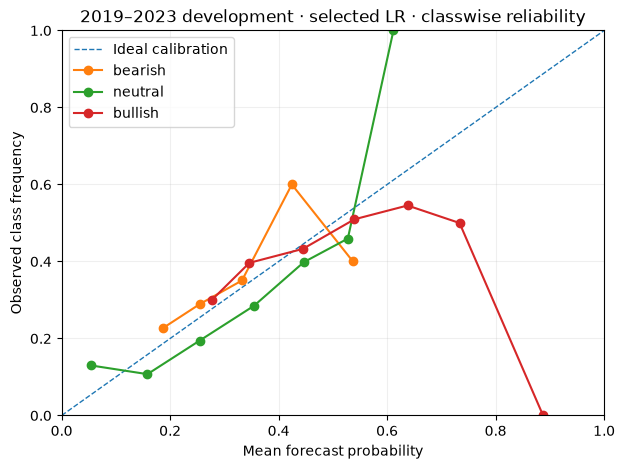

,class,bin,n,mean_predicted,observed_frequency
0,bearish,1,22,0.187055,0.227273
1,bearish,2,786,0.255528,0.290076
2,bearish,3,385,0.332437,0.350649
3,bearish,4,30,0.424362,0.600000
4,bearish,5,5,0.537012,0.400000
5,neutral,0,77,0.054717,0.129870
6,neutral,1,149,0.158209,0.107383
7,neutral,2,252,0.254316,0.194444
8,neutral,3,330,0.354506,0.284848
9,neutral,4,344,0.446431,0.398256


Development ECE by class (descriptive; bins=10):


,class,ECE_10_bins
0,bearish,0.033392
1,bullish,0.036714
2,neutral,0.060116


Development results selected the model; do not claim confirmatory significance from these scores.


In [15]:
def paired_scores_and_interval(model_rows, prior_rows, block_length=BOOT_BLOCK_LENGTH,
                               replicates=BOOT_REPLICATES, seed=BOOT_SEED):
    a = model_rows.sort_values("session_date").reset_index(drop=True)
    b = prior_rows.sort_values("session_date").reset_index(drop=True)
    assert len(a) == len(b) and len(a) > block_length
    assert np.array_equal(a.session_date.to_numpy(), b.session_date.to_numpy())
    assert np.array_equal(a.actual_target.to_numpy(),b.actual_target.to_numpy())
    paired = a.brier.to_numpy() - b.brier.to_numpy()
    rng = np.random.default_rng(seed)
    n = len(paired)
    starts = np.arange(n-block_length+1)
    means = np.empty(replicates,dtype=float)
    nblocks = int(np.ceil(n/block_length))
    for r in range(replicates):
        s = rng.choice(starts,size=nblocks,replace=True)
        indices = np.concatenate([np.arange(begin,begin+block_length) for begin in s])[:n]
        means[r] = paired[indices].mean()
    return {
        "n":int(n),
        "model_mean_brier":float(a.brier.mean()),
        "expanding_prior_mean_brier":float(b.brier.mean()),
        "paired_delta_brier":float(paired.mean()),
        "ci_95_low":float(np.quantile(means,0.025)),
        "ci_95_high":float(np.quantile(means,0.975)),
        "bootstrap_block_length":int(block_length),
        "bootstrap_replicates":int(replicates),
        "bootstrap_seed":int(seed),
    }


def classwise_calibration(rows, bins=10):
    table = []
    for label in CLASS_ORDER:
        probabilities = rows[f"p_{label}"].to_numpy(dtype=float)
        outcomes = (rows.actual_target.astype(str).to_numpy() == label).astype(float)
        ids = np.minimum((probabilities*bins).astype(int),bins-1)
        for bin_id in range(bins):
            keep = ids == bin_id
            if keep.any():
                table.append({"class":label,"bin":bin_id,"n":int(keep.sum()),
                              "mean_predicted":float(probabilities[keep].mean()),
                              "observed_frequency":float(outcomes[keep].mean())})
    return pd.DataFrame(table)


def classwise_ece(rows, bins=10):
    table = classwise_calibration(rows,bins=bins)
    totals = table.groupby("class",sort=False)["n"].transform("sum")
    table["weighted_absolute_gap"] = (table["n"]/totals) * (
        table["mean_predicted"]-table["observed_frequency"]
    ).abs()
    return table.groupby("class",as_index=False)["weighted_absolute_gap"].sum().rename(
        columns={"weighted_absolute_gap":"ECE_10_bins"}
    )


def plot_calibration(rows, heading):
    table = classwise_calibration(rows)
    fig, ax = plt.subplots(figsize=(7,5))
    ax.plot([0,1],[0,1],linestyle="--",linewidth=1,label="Ideal calibration")
    for label in CLASS_ORDER:
        t = table.loc[table["class"]==label]
        ax.plot(t.mean_predicted,t.observed_frequency,marker="o",label=label)
    ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean forecast probability",
           ylabel="Observed class frequency",title=heading)
    ax.grid(alpha=0.2)
    ax.legend()
    plt.show()
    return table

dev_primary_comparison = paired_scores_and_interval(dev_model,dev_prior)
print("DEVELOPMENT-ONLY PRIMARY COMPARISON (selected C; optimistic for inference):")
display(pd.DataFrame([dev_primary_comparison]))
calibration_table_dev = plot_calibration(dev_model,"2019–2023 development · selected LR · classwise reliability")
display(calibration_table_dev)
print("Development ECE by class (descriptive; bins=10):")
display(classwise_ece(dev_model))
print("Development results selected the model; do not claim confirmatory significance from these scores.")

## 10. Registered exploratory diagnostics — no test-set access

The frozen parquet has **no session-level bar-count/coverage indicator**. A coverage-stratified result **cannot** be computed accurately from this 16-column table. We report it as **unavailable**, rather than creating a made-up proxy or joining licensed raw data without a provenance amendment.

Development observations may be broken down descriptively by time. This does **not** constitute a pre-2012 market-hours-regime test because 2010–2012 have no scored walk-forward development predictions in this evaluation.

In [16]:
# Development period only; historical subperiods are descriptive, not alternate primary tests.
def subperiod_comparison(model_rows,prior_rows,periods):
    out = []
    for name, start, end in periods:
        ma = model_rows.loc[model_rows.session_date.between(start,end)]
        pa = prior_rows.loc[prior_rows.session_date.between(start,end)]
        if len(ma) and len(ma) == len(pa):
            x=paired_scores_and_interval(ma,pa,block_length=min(BOOT_BLOCK_LENGTH,len(ma)-1),
                                         replicates=BOOT_REPLICATES,seed=BOOT_SEED)
            out.append({"subperiod":name,**x})
    return pd.DataFrame(out)

development_regime_diagnostic = subperiod_comparison(dev_model,dev_prior,[
    ("2019–2021", "2019-01-01","2021-12-31"),
    ("2022–2023", "2022-01-01","2023-12-31"),
])
display(development_regime_diagnostic)
print("COVERAGE SENSITIVITY: NOT COMPUTABLE FROM FROZEN 16-COLUMN MODELING PARQUET")
print("PRE-2012 SCORED MARKET-HOURS COMPARISON: NOT AVAILABLE UNDER 2019–2023 DEVELOPMENT SPLIT")

,subperiod,n,model_mean_brier,expanding_prior_mean_brier,paired_delta_brier,ci_95_low,ci_95_high,bootstrap_block_length,bootstrap_replicates,bootstrap_seed
0,2019–2021,738,0.632690,0.663543,-0.030853,-0.044650,-0.014757,20,2000,42
1,2022–2023,490,0.665792,0.675280,-0.009488,-0.025471,0.003888,20,2000,42


COVERAGE SENSITIVITY: NOT COMPUTABLE FROM FROZEN 16-COLUMN MODELING PARQUET
PRE-2012 SCORED MARKET-HOURS COMPARISON: NOT AVAILABLE UNDER 2019–2023 DEVELOPMENT SPLIT


### Additional development-only stability and bearish-class diagnostics (post-development, descriptive)

These diagnostics are added **after** the original model-selection run. They must **never** be used to choose another `C`, feature set, threshold, metric, or final-test protocol. The development-period C selection and primary model comparison remain unchanged. Each interval below is a descriptive breakdown of already generated out-of-sample development probabilities. Directional recall is **not** a surrogate for the proper probabilistic primary score.

In [17]:
# No additional fitting, no final-period predictions, no change to selected C.
by_year_diagnostics = subperiod_comparison(dev_model, dev_prior, [
    (str(year),f"{year}-01-01",f"{year}-12-31") for year in range(2019,2024)
])
joined = (dev_model[["session_date", "quarter", "actual_target", "brier"]]
          .merge(dev_prior[["session_date", "brier"]],
                 on="session_date", how="inner", validate="one_to_one",
                 suffixes=("_model", "_prior")))
joined["paired_delta_brier"] = joined["brier_model"] - joined["brier_prior"]
quarter_stability = joined.groupby("quarter", sort=True).agg(
    n=("paired_delta_brier","size"),
    mean_delta_brier=("paired_delta_brier","mean"),
    mean_model_brier=("brier_model","mean"),
    mean_prior_brier=("brier_prior","mean")
).reset_index()
quarter_stability["four_quarter_mean_delta"] = (
    quarter_stability["mean_delta_brier"].rolling(4,min_periods=4).mean()
)
assert len(quarter_stability)==20 and int(quarter_stability.n.sum()) == 1228

bearish_support = int((dev_model.actual_target == "bearish").sum())
bearish_detected = int(((dev_model.actual_target == "bearish") &
                        (dev_model.argmax_target == "bearish")).sum())
bearish_recall = bearish_detected / bearish_support if bearish_support else float("nan")
class_summary = classwise_directional_report(dev_model)
class_summary["selection_use"] = "descriptive only — do not tune on this report"
print("DEVELOPMENT YEAR-BY-YEAR BRIER: DESCRIPTIVE ONLY")
display(by_year_diagnostics)
print("DEVELOPMENT QUARTERLY PAIRED BRIER: DESCRIPTIVE ONLY")
display(quarter_stability)
print(f"Bearish argmax recall: {bearish_detected}/{bearish_support} = {bearish_recall:.3%}")
print("The selected model may assign useful probabilities yet rarely predict bearish as argmax.")
if bearish_support and bearish_recall < 0.10:
    print("WARNING: bearish directional recall below 10%; do NOT retune using the locked test.")
display(class_summary)

DEVELOPMENT YEAR-BY-YEAR BRIER: DESCRIPTIVE ONLY


,subperiod,n,model_mean_brier,expanding_prior_mean_brier,paired_delta_brier,ci_95_low,ci_95_high,bootstrap_block_length,bootstrap_replicates,bootstrap_seed
0,2019,245,0.631960,0.653840,-0.021880,-0.040412,0.000856,20,2000,42
1,2020,246,0.629923,0.675208,-0.045285,-0.083794,-0.018678,20,2000,42
2,2021,247,0.636169,0.661550,-0.025381,-0.041850,-0.009991,20,2000,42
3,2022,246,0.664852,0.686858,-0.022007,-0.048627,0.001287,20,2000,42
4,2023,244,0.666741,0.663607,0.003134,-0.009174,0.017176,20,2000,42


DEVELOPMENT QUARTERLY PAIRED BRIER: DESCRIPTIVE ONLY


,quarter,n,mean_delta_brier,mean_model_brier,mean_prior_brier,four_quarter_mean_delta
0,2019Q1,60,-0.005455,0.648460,0.653915,NaN
1,2019Q2,62,-0.015709,0.641875,0.657584,NaN
2,2019Q3,62,-0.036680,0.633067,0.669747,NaN
3,2019Q4,61,-0.029266,0.604529,0.633795,-0.021777
4,2020Q1,61,-0.065393,0.628877,0.694270,-0.036762
5,2020Q2,62,-0.078346,0.598881,0.677226,-0.052421
6,2020Q3,62,-0.036330,0.634235,0.670565,-0.052334
7,2020Q4,61,-0.000676,0.658139,0.658815,-0.045186
8,2021Q1,60,-0.034734,0.640249,0.674982,-0.037521
9,2021Q2,62,-0.043074,0.601566,0.644639,-0.028703


Bearish argmax recall: 12/388 = 3.093%
The selected model may assign useful probabilities yet rarely predict bearish as argmax.


,class,precision,recall,f1,support,selection_use
0,bearish,0.444444,0.030928,0.057831,388,descriptive only — do not tune on this report
1,neutral,0.386760,0.649123,0.484716,342,descriptive only — do not tune on this report
2,bullish,0.452951,0.570281,0.504889,498,descriptive only — do not tune on this report


## 11. Save full development probabilities, scores and model-selection manifest (local only)

**Write-once policy:** this hardened notebook saves in a separate, content-addressed local folder keyed by the source, parquet and committed protocol. Identical repeated development runs are allowed; different bytes at the same path cause an error. Previously exported development results are not overwritten. When required, original-selection reconciliation is **mandatory**: it verifies the original development manifest's existence, frozen data/protocol identifiers, selected `C`, primary Brier difference, and original manifest hash **before** new approved artifacts can be saved. The holdout gate checks the persisted evidence again. The corrected baseline-provenance columns affect only audit records, not the probabilities or scores.

In [18]:
# ------------------------------------------------------------
# Immutable, content-addressed development artifacts (local only).
# NEVER overwrite the previous Notebook 09 development folder.
# If the exact same version is rerun, identical bytes are accepted;
# changed bytes at an existing path cause a hard stop.
# ------------------------------------------------------------
import os
import io

SOURCE_CONTEXT = {
    "dataset_sha256": actual_hash,
    "metadata_sha256": sha256_file(METADATA_PATH),
    "protocol_sha256": PROTOCOL_SHA256,
    "notebook_source_sha256": NOTEBOOK_SOURCE_SHA256,
    "experiment_version": EXPERIMENT_VERSION,
    "feature_columns": FEATURE_COLUMNS,
    "C_grid": list(C_GRID),
    "fixed_training_ends": [INITIAL_TRAIN_END, DEV_END, TEST_END],
}
SOURCE_CONTEXT_SHA256 = hashlib.sha256(json.dumps(
    SOURCE_CONTEXT,sort_keys=True,separators=(",", ":")
).encode("utf-8")).hexdigest()

# An entirely separate directory from the previously executed Notebook 09.
OUTPUT_DIR = PROJECT_ROOT / "data/processed/es_daily_nb09_v0_1_hardened" / (
    "run_" + SOURCE_CONTEXT_SHA256[:16]
)
ORIGINAL_DEVELOPMENT_MANIFEST = (PROJECT_ROOT /
    "data/processed/es_daily_nb09_v0_1/development_selection_manifest_v0_1.json")

def write_once_bytes(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        if path.read_bytes() == data:
            print("UNCHANGED: existing immutable artifact", path.name)
            return
        raise FileExistsError(
            f"Immutable artifact differs: {path}. Never overwrite a prior research record."
        )
    try:
        with path.open("xb") as stream:
            stream.write(data)
            stream.flush()
            os.fsync(stream.fileno())
    except FileExistsError:
        if path.read_bytes() != data:
            raise

def write_once_json(path, data):
    raw = (json.dumps(data,sort_keys=True,indent=2,
                      ensure_ascii=False,default=str) + "\n").encode("utf-8")
    write_once_bytes(path, raw)

def write_once_csv(path, table):
    raw = table.to_csv(index=False,float_format="%.17g").encode("utf-8")
    write_once_bytes(path, raw)

def compare_original_development():
    if not ORIGINAL_DEVELOPMENT_MANIFEST.is_file():
        print("PREVIOUS DEVELOPMENT MANIFEST: MISSING. Mandatory original-run reconciliation cannot pass.")
        return {"prior_manifest_found":False,"original_agreement_verified":False,
                "failure_reason":"Required earlier development manifest not found at frozen path"}
    previous = json.loads(ORIGINAL_DEVELOPMENT_MANIFEST.read_text(encoding="utf-8"))
    assert previous["dataset_sha256"] == actual_hash
    assert previous["protocol_sha256"] == PROTOCOL_SHA256
    assert list(previous["candidate_C_values"]) == list(C_GRID)
    if float(previous["selected_C"]) != float(SELECTED_C):
        raise RuntimeError("Revised selection differs from original. Do not open holdout; investigate.")
    old_delta = float(previous["development_comparison"]["paired_delta_brier"])
    new_delta = float(dev_primary_comparison["paired_delta_brier"])
    if abs(old_delta - new_delta) > 1e-7:
        raise RuntimeError("Revised development Brier delta differs from original (>1e-7). Investigate.")
    print("ORIGINAL vs REVISED DEVELOPMENT: PASS; C and primary delta agree.")
    return {"prior_manifest_found":True,"original_agreement_verified":True,
            "original_manifest_sha256":sha256_file(ORIGINAL_DEVELOPMENT_MANIFEST),
            "original_selected_C":float(previous["selected_C"]),
            "original_paired_delta_brier":old_delta}

ORIGINAL_AGREEMENT = compare_original_development()
ORIGINAL_AGREEMENT_VERIFIED = bool(
    ORIGINAL_AGREEMENT.get("prior_manifest_found") is True
    and ORIGINAL_AGREEMENT.get("original_agreement_verified") is True
    and ORIGINAL_AGREEMENT.get("original_manifest_sha256")
    and ORIGINAL_DEVELOPMENT_MANIFEST.is_file()
    and sha256_file(ORIGINAL_DEVELOPMENT_MANIFEST)
        == ORIGINAL_AGREEMENT["original_manifest_sha256"]
)
if REQUIRE_ORIGINAL_DEVELOPMENT_AGREEMENT and not ORIGINAL_AGREEMENT_VERIFIED:
    raise RuntimeError(
        "Mandatory original-development reconciliation FAILED: "
        "the original manifest is absent or not verified. "
        f"Required file: {ORIGINAL_DEVELOPMENT_MANIFEST}. "
        "Restore the authentic original manifest from your previous Notebook 09 "
        "development run and rerun. Do NOT create a substitute or bypass "
        "this safeguard to unlock the final test. "
        "No new development artifacts were written by this cell."
    )
print("ORIGINAL DEVELOPMENT RECONCILIATION:",
      "VERIFIED" if ORIGINAL_AGREEMENT_VERIFIED else "NOT VERIFIED (holdout unavailable)")

# Preserve the authentic ORIGINAL manifest in addition to its externally retained
# original location; never fabricate the original from revised results.
# An unchanged byte-for-byte copy is useful if the source directory is moved.
# It is NOT accepted as a substitute for the original by the locked-test gate.
ORIGINAL_MANIFEST_BYTES = ORIGINAL_DEVELOPMENT_MANIFEST.read_bytes()
assert hashlib.sha256(ORIGINAL_MANIFEST_BYTES).hexdigest() == ORIGINAL_AGREEMENT["original_manifest_sha256"]


DEVELOPMENT_FILES = {
    "development_probabilities_v0_1.csv": dev_selected,
    "development_hyperparameter_grid_v0_1.csv": selection_table,
    "development_calibration_v0_1.csv": calibration_table_dev,
    "development_classwise_metrics_v0_1.csv": class_summary,
    "development_quarterly_scores_v0_1.csv": dev_selected.groupby(["quarter","model"],sort=True).agg(
        n=("brier","size"),mean_brier=("brier","mean"),
        mean_log_loss=("log_loss","mean")).reset_index(),
    "development_regime_diagnostics_v0_1.csv": development_regime_diagnostic,
    "development_year_diagnostics_v0_1.csv": by_year_diagnostics,
    "development_quarter_stability_v0_1.csv": quarter_stability,
}

def development_manifest():
    return {
        "experiment":"ES Daily Forward Experiment",
        "experiment_version":EXPERIMENT_VERSION,
        "status":"development-selected; final holdout NOT scored",
        "notebook":"notebooks/09_es_daily_walkforward_modeling.ipynb",
        "prior_selection_reconciled":ORIGINAL_AGREEMENT_VERIFIED,
        "original_development_reconciliation_required":REQUIRE_ORIGINAL_DEVELOPMENT_AGREEMENT,
        "source_context_sha256":SOURCE_CONTEXT_SHA256,
        "notebook_source_sha256":NOTEBOOK_SOURCE_SHA256,
        "dataset_sha256":actual_hash,
        "metadata_sha256":sha256_file(METADATA_PATH),
        "protocol_sha256":PROTOCOL_SHA256,
        "git_head":GIT_HEAD,"git_branch":GIT_BRANCH,
        "notebook_08_producer_commit":NOTEBOOK_08_PRODUCER_COMMIT,
        "python_environment":ENVIRONMENT_INFO,
        "installed_package_inventory_sha256": hashlib.sha256(
            (json.dumps(INSTALLED_PACKAGE_VERSIONS, sort_keys=True, indent=2) + "\n").encode("utf-8")
        ).hexdigest(),
        "original_manifest_snapshot_sha256": ORIGINAL_AGREEMENT["original_manifest_sha256"],
        "class_order":list(CLASS_ORDER),"feature_columns":FEATURE_COLUMNS,
        "historical_dead_zone_pct":HISTORICAL_DEAD_ZONE_PCT,
        "train_until":INITIAL_TRAIN_END,"development_start":DEV_START,
        "development_end":DEV_END,"locked_test_start":TEST_START,
        "locked_test_end":TEST_END,
        "quarterly_expanding_refit":True,"training_only_scaling":True,
        "selection_metric":"summed_multiclass_brier",
        "class_prior_alpha":PRIOR_ALPHA,"rolling_baseline_n":ROLLING_PRIOR_N,
        "candidate_C_values":list(C_GRID),"selected_C":SELECTED_C,
        "solver":SOLVER,"max_iter":MAX_ITER,"class_weight":None,
        "bootstrap":{"block_length":BOOT_BLOCK_LENGTH,"replicates":BOOT_REPLICATES,"seed":BOOT_SEED},
        "development_comparison":dev_primary_comparison,
        "original_development_agreement":ORIGINAL_AGREEMENT,
        "baseline_provenance_contract": {
            "LR_training_end_date":"end of quarterly fitted training window",
            "prior_training_end_date":"most recent eligible settled session strictly before forecast",
            "prior_information_end_date":"same as prior training_end_date",
            "baseline_history_start_date":"first eligible session supplying labels to this baseline",
            "baseline_history_n":"number of earlier settled sessions in prior estimate",
            "uniform_training_end_date":None,
            "quarterly_fit_end_date":"reference cutoff for the quarterly Logistic Regression fold",
        },
        "post_development_diagnostics_not_for_selection":True,
        "holdout_scored":False,
        "development_artifact_sha256":{
            name:sha256_file(OUTPUT_DIR/name) for name in DEVELOPMENT_FILES
        },
        "limitations":[
            "pre-2012 regime lacks scored development forecasts",
            "coverage diagnostics absent from 16-column parquet",
            "continuous futures roll point-in-time fidelity remains externally unaudited",
            "range and volume predictor source values cannot be independently reconstructed from modeling parquet"
        ]
    }

if SAVE_DEVELOPMENT_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    write_once_bytes(OUTPUT_DIR / "original_development_manifest_snapshot_v0_1.json", ORIGINAL_MANIFEST_BYTES)
    write_once_json(OUTPUT_DIR / "installed_package_inventory_v0_1.json", INSTALLED_PACKAGE_VERSIONS)
    for name,frame in DEVELOPMENT_FILES.items():
        write_once_csv(OUTPUT_DIR/name,frame)
    selection_path = OUTPUT_DIR/"development_selection_manifest_v0_1.json"
    if selection_path.exists():
        old_manifest = json.loads(selection_path.read_text(encoding="utf-8"))
        if (old_manifest.get("source_context_sha256") != SOURCE_CONTEXT_SHA256 or
            old_manifest.get("dataset_sha256") != actual_hash or
            float(old_manifest.get("selected_C")) != SELECTED_C or
            old_manifest.get("prior_selection_reconciled") is not ORIGINAL_AGREEMENT_VERIFIED or
            old_manifest.get("original_development_agreement") != ORIGINAL_AGREEMENT or
            old_manifest.get("baseline_provenance_contract") != development_manifest()["baseline_provenance_contract"] or
            old_manifest.get("development_artifact_sha256") != {
                name:sha256_file(OUTPUT_DIR/name) for name in DEVELOPMENT_FILES
            }):
            raise RuntimeError("Existing selection manifest disagrees with the current immutable artifacts.")
        print("PRESERVED: existing immutable selection manifest from the first development run")
    else:
        write_once_json(selection_path,development_manifest())
    SELECTION_MANIFEST_SHA256 = sha256_file(selection_path)
    # The template is NOT an authorization. Copy and explicitly edit it only
    # after external review/sign-off; the gate insists on approved:true.
    approval_template = {
        "approved":False,
        "approver":"",
        "approved_at_utc":"",
        "approved_git_commit":"",
        "acknowledge_no_holdout_driven_retuning":False,
        "acknowledge_upstream_point_in_time_limits":False,
        "acknowledge_unavailable_bar_coverage_audit":False,
        "acknowledge_irreversible_one_time_evaluation":False,
        "selection_manifest_sha256":SELECTION_MANIFEST_SHA256,
        "source_context_sha256":SOURCE_CONTEXT_SHA256,
        "notebook_source_sha256":NOTEBOOK_SOURCE_SHA256,
        "protocol_sha256":PROTOCOL_SHA256,
        "dataset_sha256":actual_hash,
        "approved_selected_C":SELECTED_C,
        "review_statement":"I reviewed the development evidence and authorize one unrevised final evaluation."
    }
    write_once_json(OUTPUT_DIR/"LOCKED_APPROVAL_TEMPLATE.json", approval_template)
    print("WRITE-ONCE DEVELOPMENT ARTIFACTS: PASS", OUTPUT_DIR)
    print("Selection-manifest SHA-256:", SELECTION_MANIFEST_SHA256)
else:
    print("Development exports disabled; the locked gate will remain closed.")

print("LOCKED HOLDOUT: STILL UNSCORED by development cells")

ORIGINAL vs REVISED DEVELOPMENT: PASS; C and primary delta agree.
ORIGINAL DEVELOPMENT RECONCILIATION: VERIFIED
WRITE-ONCE DEVELOPMENT ARTIFACTS: PASS C:\Users\melny\Market-Mood-Forecasting\data\processed\es_daily_nb09_v0_1_hardened\run_e171b45d4bbe216a
Selection-manifest SHA-256: 33a2a1c9a0f842a167679c1864612edff7da39cd779e7f6b2e5c9243203b8a43
LOCKED HOLDOUT: STILL UNSCORED by development cells


## 12. Lock checkpoint: research sign-off before final evaluation

The v0.1 selected `C` and the development manifest must be preserved before opening the 2024–September 2026 holdout. The frozen protocol must already be committed and pushed, and the experiment must remain on the experimental branch.

**Mandatory original-manifest proof:** with `REQUIRE_ORIGINAL_DEVELOPMENT_AGREEMENT=True`, an authentic `data/processed/es_daily_nb09_v0_1/development_selection_manifest_v0_1.json` must exist and pass reconciliation. A prior hardening-run manifest is not a substitute for the original. The authorization gate checks persisted reconciliation and the original manifest's current SHA-256. Missing/changed evidence means **no holdout evaluation**.

**Before ever authorizing the test:** inspect development results, document the *selected* configuration without modifying the preregistered algorithm, verify point-in-time and platform-target compatibility limitations, and decide consciously whether this is the one designated historical test. If any method change is justified, document it in a protocol amendment **without consulting holdout results**.

There is no automated live API access in this notebook.
**Git freeze before approval:** save the current notebook at the canonical path, review outputs for credentials and licensed market-data redistribution, commit the notebook code and any approved protocol amendments on `experiment/headline-arena-es-daily`, push, then run `git fetch origin`. The holdout gate verifies that **Git HEAD is locally synchronized with origin**, the full committed Notebook 09 *source* matches the current modeling source (apart from the two explicitly permitted authorization literals), and the committed protocol matches the working copy (accounting for Windows CRLF normalization). A development Run All may happen before that Git commit; an approved holdout run may not. Git checks here rely on your locally fetched remote-tracking ref, not a live GitHub API check.

**Development evidence preservation:** the authentic original manifest is copied byte-for-byte to the immutable run directory as an additional archive, not a replacement for its original location; installed package name/version records are also stored as local write-once research artifacts. Keep these local outputs private and backed up. The environment inventory is not a cross-platform dependency lockfile.

**Additional approval procedure:** after inspecting immutable development artifacts and confirming there is no post-selection tuning, copy `LOCKED_APPROVAL_TEMPLATE.json` to `LOCKED_APPROVAL.json` *inside the content-addressed output folder*, change `approved` to `true`, fill `approver`, a valid UTC `approved_at_utc`, and the actual pushed `approved_git_commit`, set each of the four `acknowledge_...` fields to `true` **only after personally reviewing those conditions**, and leave all generated hashes, selected `C`, and model design unchanged. Preserve the resulting approval as a local research record. Then deliberately set the two final-test switches in Section 1. The one-time `LOCKED_EVALUATION_STARTED.json` marker is created **before** final predictions; even an interrupted run is considered a consumed holdout. Do not bypass the marker to try again.

In [19]:
# ------------------------------------------------------------
# RESEARCH_HOLDOUT_GATE_SENTINEL_V0_1
# Researcher authorization and BEFORE-FIRST-PREDICTION reservation.
# A separate user-signed JSON plus both opt-in settings are mandatory.
# The started marker is written BEFORE the holdout computation, so a crash
# cannot silently allow a second try at the supposedly one-time holdout.
# ------------------------------------------------------------
FINAL_TEST_AUTHORIZED = False
if not (RUN_LOCKED_FINAL_TEST and FINAL_TEST_CONFIRMATION == REQUIRED_FINAL_TEST_PHRASE):
    print("LOCKED TEST: NOT AUTHORIZED. No 2024–2026 scores were computed.")
else:
    if not SAVE_DEVELOPMENT_OUTPUTS:
        raise RuntimeError("Refusing holdout: immutable development exports must be enabled")
    selection_path = OUTPUT_DIR/"development_selection_manifest_v0_1.json"
    approval_path = OUTPUT_DIR/"LOCKED_APPROVAL.json"
    start_marker = OUTPUT_DIR/"LOCKED_EVALUATION_STARTED.json"
    completion_marker = OUTPUT_DIR/"LOCKED_final_evaluation_manifest_v0_1.json"
    if start_marker.exists() or completion_marker.exists():
        raise FileExistsError(
            "This holdout has already been started or completed. Do not rerun. "
            "If a crash occurred, preserve the partial audit and report it."
        )
    if not selection_path.is_file() or not approval_path.is_file():
        raise FileNotFoundError(
            "Selection manifest or explicitly approved LOCKED_APPROVAL.json missing. "
            "LOCKED_APPROVAL_TEMPLATE.json is never sufficient."
        )
    saved = json.loads(selection_path.read_text(encoding="utf-8"))
    approval = json.loads(approval_path.read_text(encoding="utf-8"))
    artifact_hashes = saved["development_artifact_sha256"]
    for name,known_hash in artifact_hashes.items():
        if sha256_file(OUTPUT_DIR/name)!=known_hash:
            raise RuntimeError(f"Frozen development artifact drift detected: {name}")
    # A local approval JSON is an attestation, NOT a cryptographic signature.
    # Only an explicit affirmative approval plus Git-frozen source/protocol
    # may open the holdout; normal Run All never calls the Git holdout check.
    GIT_HOLDOUT_ATTESTATION = assert_git_handoff_ready_for_holdout()
    from datetime import timedelta
    try:
        approved_time = datetime.fromisoformat(
            str(approval.get("approved_at_utc", "")).replace("Z", "+00:00")
        )
        approval_timestamp_valid = (
            approved_time.tzinfo is not None and
            approved_time.utcoffset() == timedelta(0) and
            approved_time <= datetime.now(timezone.utc)
        )
    except (ValueError, TypeError, OverflowError):
        approval_timestamp_valid = False
    checks = {
        "approved_true":approval.get("approved") is True,
        "approval_utc_timestamp_valid": approval_timestamp_valid,
        "approved_committed_git_revision": approval.get("approved_git_commit") == GIT_HEAD,
        "explicit_no_holdout_retuning": approval.get("acknowledge_no_holdout_driven_retuning") is True,
        "acknowledged_point_in_time_limitations": approval.get("acknowledge_upstream_point_in_time_limits") is True,
        "acknowledged_bar_coverage_limitation": approval.get("acknowledge_unavailable_bar_coverage_audit") is True,
        "acknowledged_one_time_consumption": approval.get("acknowledge_irreversible_one_time_evaluation") is True,
        "approver":bool(str(approval.get("approver","")).strip()),
        "approved_at":bool(str(approval.get("approved_at_utc","")).strip()),
        "selection_sha":approval.get("selection_manifest_sha256")==sha256_file(selection_path),
        "source_context":approval.get("source_context_sha256")==SOURCE_CONTEXT_SHA256,
        "source_code":approval.get("notebook_source_sha256")==NOTEBOOK_SOURCE_SHA256,
        "protocol":approval.get("protocol_sha256")==PROTOCOL_SHA256,
        "dataset":approval.get("dataset_sha256")==actual_hash,
        "C_approved":approval.get("approved_selected_C")==SELECTED_C,
        "saved_C":saved["selected_C"]==SELECTED_C,
        "saved_not_scored":saved["holdout_scored"] is False,
        "saved_git_branch":saved["git_branch"]==GIT_BRANCH,
        "saved_features":saved["feature_columns"]==FEATURE_COLUMNS,
        "saved_C_grid":saved["candidate_C_values"]==list(C_GRID),
        "original_snapshot_present": (OUTPUT_DIR / "original_development_manifest_snapshot_v0_1.json").is_file(),
        "original_snapshot_identical": (
            (OUTPUT_DIR / "original_development_manifest_snapshot_v0_1.json").is_file()
            and sha256_file(OUTPUT_DIR / "original_development_manifest_snapshot_v0_1.json")
                == saved.get("original_manifest_snapshot_sha256")
        ),
        "environment_inventory_unchanged": (
            (OUTPUT_DIR / "installed_package_inventory_v0_1.json").is_file()
            and sha256_file(OUTPUT_DIR / "installed_package_inventory_v0_1.json")
                == saved.get("installed_package_inventory_sha256")
        ),
    }
    if REQUIRE_ORIGINAL_DEVELOPMENT_AGREEMENT:
        agreement = saved.get("original_development_agreement", {})
        expected_original_hash = agreement.get("original_manifest_sha256")
        checks["original_manifest_present"] = ORIGINAL_DEVELOPMENT_MANIFEST.is_file()
        checks["original_agreement_recorded"] = (
            saved.get("original_development_reconciliation_required") is True
            and saved.get("prior_selection_reconciled") is True
            and agreement.get("prior_manifest_found") is True
            and agreement.get("original_agreement_verified") is True
            and ORIGINAL_AGREEMENT_VERIFIED is True
        )
        checks["original_manifest_digest_unchanged"] = bool(
            expected_original_hash
            and ORIGINAL_DEVELOPMENT_MANIFEST.is_file()
            and sha256_file(ORIGINAL_DEVELOPMENT_MANIFEST) == expected_original_hash
            and ORIGINAL_AGREEMENT.get("original_manifest_sha256") == expected_original_hash
        )
        checks["original_selection_and_delta_still_agree"] = (
            ORIGINAL_AGREEMENT_VERIFIED
            and agreement == ORIGINAL_AGREEMENT
        )
    failed = [key for key,ok in checks.items() if not ok]
    if failed:
        raise RuntimeError("Locked-test authorization failed: "+", ".join(failed))

    # Critical integrity checkpoint: the model/scoring code that actually ran
    # must be identical to the canonical saved source, in a fresh Run All.
    # This happens BEFORE creating the one-time evaluation-start marker.
    assert_executed_source_chain_matches_saved_notebook(
        NOTEBOOK_PATH, "# RESEARCH_HOLDOUT_GATE_SENTINEL_V0_1"
    )

    # Reserve the one-time holdout BEFORE reading scores/predicting on it.
    write_once_json(start_marker, {
        "state":"STARTED / holdout permanently consumed (including after crash)",
        "started_utc":datetime.now(timezone.utc).isoformat(),
        "approval_sha256":sha256_file(approval_path),
        "selection_manifest_sha256":sha256_file(selection_path),
        "source_context_sha256":SOURCE_CONTEXT_SHA256,
        "code_sha256":NOTEBOOK_SOURCE_SHA256,
        "raw_code_sha256_at_approval":NOTEBOOK_RAW_SOURCE_SHA256,
        "dataset_sha256":actual_hash,
        "git_handoff_attestation":GIT_HOLDOUT_ATTESTATION,
        "original_manifest_snapshot_sha256":sha256_file(
            OUTPUT_DIR / "original_development_manifest_snapshot_v0_1.json"
        ),
        "installed_package_inventory_sha256":sha256_file(
            OUTPUT_DIR / "installed_package_inventory_v0_1.json"
        ),
    })
    FINAL_TEST_AUTHORIZED = True
    print("LOCKED TEST AUTHORIZED: one-time START marker saved BEFORE evaluation")

LOCKED TEST: NOT AUTHORIZED. No 2024–2026 scores were computed.


## 13. **Locked final test** — gated, never runs during ordinary Run All

**Hard rule:** keep `RUN_LOCKED_FINAL_TEST = False` for development. After the research sign-off, change the two authorization settings in Section 1 deliberately, rerun the notebook, and preserve the entire final-test result without using it to tune/reselect the model. Quarterly refits may use only settled earlier dates, including earlier dates from the final period.

If the gate is closed, the next cells do nothing except report that the holdout remains locked.
**One-run policy:** reopening a Jupyter notebook after an authorized run must not repeat final scoring. `LOCKED_EVALUATION_STARTED.json` is a safety stop even if the final manifest was never written. Treat crashes as reportable test-execution failures, not invitations to evaluate again.

In [20]:
# This is the ONLY cell that fits a model on final-period quarter boundaries
# or generates final-period forecast probabilities and evaluation metrics.
if not FINAL_TEST_AUTHORIZED:
    print("SKIPPED: locked 2024–2026 evaluation is disabled")
else:
    final_parts = []
    final_baseline_parts = []
    for fold in test_folds:
        pred, training_end = fit_predict_fold(fold,SELECTED_C)
        final_parts.append(make_rows(fold,SELECTED_MODEL_NAME,pred,training_end))
        for label in ("uniform","expanding_prior","rolling_252_prior"):
            final_baseline_parts.append(make_baseline_rows(fold,label))
    final_model = score_predictions(pd.concat(final_parts,ignore_index=True))
    final_baseline = score_predictions(pd.concat(final_baseline_parts,ignore_index=True))
    assert len(final_model) == 673
    assert final_baseline.groupby("model").size().eq(673).all()
    final_prior = final_baseline.loc[final_baseline.model == "expanding_prior"].copy()
    final_primary_comparison = paired_scores_and_interval(final_model,final_prior)
    final_predictions = pd.concat([final_model,final_baseline],ignore_index=True)
    assert len(final_predictions) == 673*4
    # Audit-only: no prior baseline may have used the scored session's
    # own label or a future outcome. This does not change the predictions.
    prior_final_rows = final_predictions.loc[
        final_predictions.model.isin(["expanding_prior", "rolling_252_prior"])
    ]
    assert (prior_final_rows.information_end_date < prior_final_rows.session_date).all()
    assert (prior_final_rows.training_end_date == prior_final_rows.information_end_date).all()
    assert final_predictions.loc[
        final_predictions.model == "uniform", "training_end_date"
    ].isna().all()
    print("LOCKED FINAL TEST: COMPLETED exactly once under preselected protocol")
    display(metrics_table(final_predictions))
    display(pd.DataFrame([final_primary_comparison]))

SKIPPED: locked 2024–2026 evaluation is disabled


In [21]:
# Only runs after deliberate authorization. No retraining or selection in this cell.
if not FINAL_TEST_AUTHORIZED:
    print("SKIPPED: final-test calibration/report/export")
else:
    final_calibration = plot_calibration(final_model,"2024–Sep 2026 LOCKED TEST · classwise reliability")
    display(final_calibration)
    print("LOCKED TEST secondary classwise metrics and reliability (do not retune):")
    display(classwise_directional_report(final_model))
    display(classwise_ece(final_model))
    print("Confusion matrix, true rows / predicted columns, order:", CLASS_ORDER)
    print(confusion_matrix(final_model.actual_target,final_model.argmax_target,labels=list(CLASS_ORDER)))
    final_period_diagnostics = subperiod_comparison(final_model,final_prior,[
        ("2024", "2024-01-01","2024-12-31"),
        ("2025", "2025-01-01","2025-12-31"),
        ("2026 Jan–Sep", "2026-01-01","2026-09-30"),
    ])
    display(final_period_diagnostics)
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    if not (OUTPUT_DIR / "LOCKED_EVALUATION_STARTED.json").exists():
        raise RuntimeError("Missing pre-evaluation start marker")
    if (OUTPUT_DIR / "LOCKED_final_evaluation_manifest_v0_1.json").exists():
        raise FileExistsError("Final-test manifest already exists. Refusing output overwrite.")
    write_once_csv(OUTPUT_DIR / "LOCKED_final_probabilities_v0_1.csv", final_predictions)
    write_once_csv(OUTPUT_DIR / "LOCKED_final_calibration_v0_1.csv", final_calibration)
    write_once_csv(OUTPUT_DIR / "LOCKED_final_classwise_metrics_v0_1.csv",classwise_directional_report(final_model))
    write_once_csv(OUTPUT_DIR / "LOCKED_final_quarterly_scores_v0_1.csv",
                     final_predictions.groupby(["quarter","model"],sort=True).agg(
                         n=("brier","size"),mean_brier=("brier","mean"),
                         mean_log_loss=("log_loss","mean")
                     ).reset_index())
    write_once_csv(OUTPUT_DIR / "LOCKED_final_year_diagnostics_v0_1.csv",final_period_diagnostics)
    final_manifest = {
        "experiment_version":EXPERIMENT_VERSION,"dataset_sha256":actual_hash,
        "protocol_sha256":PROTOCOL_SHA256,
        "selected_C_from_prior_development":SELECTED_C,
        "class_order":list(CLASS_ORDER),
        "final_n":673,"final_period":[TEST_START,TEST_END],
        "primary_comparison":final_primary_comparison,
        "selection_manifest_sha256":sha256_file(OUTPUT_DIR/"development_selection_manifest_v0_1.json"),
        "notebook_source_sha256":NOTEBOOK_SOURCE_SHA256,
        "notebook_raw_source_sha256_at_final":NOTEBOOK_RAW_SOURCE_SHA256,
        "source_context_sha256":SOURCE_CONTEXT_SHA256,
        "git_head":GIT_HEAD,
        "python_environment":ENVIRONMENT_INFO,
        "holdout_start_marker_sha256":sha256_file(OUTPUT_DIR/"LOCKED_EVALUATION_STARTED.json"),
        "approval_sha256":sha256_file(OUTPUT_DIR/"LOCKED_APPROVAL.json"),
        "evaluated_utc":datetime.now(timezone.utc).isoformat(),
        "no_reoptimization_on_test":True,
        "final_artifact_sha256":{
            name:sha256_file(OUTPUT_DIR/name) for name in (
                "LOCKED_final_probabilities_v0_1.csv",
                "LOCKED_final_calibration_v0_1.csv",
                "LOCKED_final_classwise_metrics_v0_1.csv",
                "LOCKED_final_quarterly_scores_v0_1.csv",
                "LOCKED_final_year_diagnostics_v0_1.csv"
            )
        },
    }
    final_manifest_path = OUTPUT_DIR/"LOCKED_final_evaluation_manifest_v0_1.json"
    if final_manifest_path.exists():
        raise FileExistsError(
            "Locked final-test manifest already exists. Do not overwrite a completed holdout."
        )
    write_once_json(final_manifest_path,final_manifest)
    print("LOCKED FINAL EVALUATION ARTIFACTS SAVED (local only):",OUTPUT_DIR)

SKIPPED: final-test calibration/report/export


## 14. Interpretation and known scientific limitations

**Development evidence:** any selected-model result from 2019–2023 is *selection-contaminated* for confirmatory inference; it is useful for model choice and diagnostics, not as unbiased proof of outperformance.

**Locked evaluation evidence:** after authorization, report the *single* predeclared 2024–September 2026 primary comparison, the paired Brier difference and dependence-aware uncertainty. Do not describe a favorable point estimate as automatically significant. Keep negative and null results.

**Structural constraints inherited from Notebook 08:**

- 2010–2012 trading-calendar/weekday exclusions complicate representativeness of training data.
- The modeling parquet contains no per-session minute-bar coverage; coverage sensitivity cannot be performed faithfully without an explicitly versioned, audited join.
- A post-2021-only final test cannot estimate pre-2012 out-of-sample skill. Do not make claims about older regimes using in-sample training metrics.
- Databento continuous front-contract mappings require a separate point-in-time availability audit before real-time deployment.
- The frozen ±0.30% history is applicable to a live Arena challenge only if that challenge's `dead_zone_pct` and settlement contract are compatible. Challenge-specific rules and API deadline always govern.
- This is not an investor-performance study: no transactions, slippage, fees or trading P&L are evaluated.
- The initial ES-only experiment does not demonstrate additional value from sentiment or event features.

**No real-time submissions are made by Notebook 09.** Any public notebook outputs and derivative forecast files require the same secrets/licensing review as Notebook 08.
**Post-development audit additions:** The independent return-lag identity checks and yearly/quarterly descriptive summaries were added after the original development run. They are transparent safeguards/diagnostics, not alternate criteria for choosing hyperparameters or resetting the locked evaluation.

**Audit correction, post-development:** Expanding/rolling class-prior predictions use earlier settled labels through the last eligible session *strictly before* each forecast, including already-settled dates within the same quarter. Their `training_end_date` is now this actual last-information date, not the quarterly LR fit cutoff. `quarterly_fit_end_date`, `information_end_date`, `baseline_history_start_date`, and `baseline_history_n` make the distinction auditable. The uniform reference has no fitted history. This change must not affect the Brier numbers. Original-development reconciliation is mandatory when configured, and the final-test gate checks the authentic manifest again. 

**Git and approval freeze (post-development):** Development can be repeated before Notebook 09 is committed, but opening the holdout additionally requires the exact normalized notebook sources and protocol to be present in the pushed experimental branch, a locally synchronized `origin` tracking ref, and a complete manual approval record bound to the reviewed Git commit and selection/dataset hashes. Original selection evidence is archived byte-for-byte, alongside an installed-package inventory. Source commits do not themselves establish predictive validity, and the local JSON approval is a human attestation rather than an authenticated digital signature.

**Reproducibility:** The content-addressed directory records an authorization-normalized model-source fingerprint, source Git HEAD/branch, frozen producer commit, protocol SHA, dataset SHA, selected C, package versions, all development prediction files and their hashes, and the explicit approval/holdout-start record. Git HEAD may precede committing this revised notebook; the canonical saved code fingerprint is also retained. A matching environment snapshot is **not** a substitute for a fully locked dependency resolution.
**Final source-integrity amendment:** the permission-normalized fingerprint is produced by Python AST-level constant substitution, not line regex. It rejects hidden same-line statements and unusual assignments. Prior to final-test reservation, a fresh full-kernel run must match the saved source exactly. Neither mechanism is a cryptographic sandbox; both are reproducible research controls.


## 15. End-of-notebook checklist

**Engineering**

- [ ] Frozen parquet SHA-256 and Notebook 08 metadata: PASS.
- [ ] Exact 16 columns and 12 frozen ES features: PASS.
- [ ] Target neutral band and class-order assertions: PASS.
- [ ] Exactly 20 feature warm-up rows, no later missing predictors: PASS.
- [ ] Chronological counts and quarterly fold feasibility: PASS.

**Development modeling**

- [ ] Uniform, expanding and trailing-252 class-frequency baselines evaluated.
- [ ] Four preregistered Logistic Regression `C` candidates evaluated with training-only scaling.
- [ ] Selected `C` chosen exclusively from 2019–2023 Brier.
- [ ] Matched-date primary Brier comparison, confidence interval and calibration produced.
- [ ] Complete per-session development forecasts and manifest saved locally.

**Locked test**

- [ ] By default: untouched. `RUN_LOCKED_FINAL_TEST=False` (correct during development).
- [ ] If/when separately authorized: exactly one 2024–September 2026 evaluation, no retuning.
- [ ] Complete probability vectors, scores and final audit manifest saved without overwrite.

**Pre-holdout freeze (new requirement)**

- [ ] Original Notebook 09 development manifest retained at its authentic path and mirrored byte-for-byte in the current content-addressed run.
- [ ] Current development selection manifest and per-session prediction files preserved write-once; package inventory saved.
- [ ] Final Notebook 09 SOURCE (not necessarily its execution outputs) and the approved protocol committed and pushed on the experiment branch.
- [ ] `git fetch origin` performed just before final authorization; local Git HEAD equals the remote-tracking experiment branch.
- [ ] `LOCKED_APPROVAL.json` personally completed with approver, UTC time, exact Git HEAD, and all four limitation/one-time acknowledgement fields.
- [ ] Saved vs executed source history verified in a newly restarted kernel before the holdout start marker.
- [ ] No final evaluation performed during this ordinary development-only run.

**Next stage, separate protocol:** prospective Headline Arena challenge inspection, target compatibility, point-in-time features, manually supervised submissions, and per-forecast external Brier comparisons.
**Hardening checklist (new revision)**

- [ ] Independently reconstructed all ten return-derived lag/rolling features from strictly earlier eligible sessions; no data-driven feature revision.
- [ ] Documented that volume/range and continuous-roll point-in-time data still require upstream validation.
- [ ] Development-only year/quarter stability and bearish recall published as descriptive diagnostics.
- [ ] Source-only code SHA-256, Git branch/HEAD, dependency versions and per-artifact hashes saved.
- [ ] Existing Notebook 09 development outputs remain untouched; reviewed artifacts are write-once.
- [ ] Unless explicitly approved, the locked holdout remains entirely unscored.
- [ ] Authorization fingerprint regression tests PASS; the exact code run in Jupyter matches the saved notebook before any holdout start.
- [ ] Original development manifest exists and reconciles; stored boolean reflects the actual check, not a constant.
- [ ] Per-forecast baseline information end dates precede the prediction dates; quarterly Logistic Regression fit dates are retained independently.
- [ ] Development probabilities and primary Brier scores remain unchanged after metadata-only provenance fixes.
